# Akustik Sinyallerle Hava Kompresörü Arıza Teşhisi

Bu defter, bir hava kompresörünün ses kaydından **sağlıklı** mı yoksa **7 arıza türünden** birinde mi olduğunu tahmin eden modeli adım adım geliştirir.

| Aşama | Adımlar | Sonuç |
|---|---|---|
| Veri hazırlama ve EDA | 1–4 | 1 800 kayıt, 8 dengeli sınıf |
| İkili model (sağlıklı / arızalı) | 4–6 | Test accuracy %97,06 |
| 8 sınıf, 9 → 14 → 18 özellik | 7–19 | Test accuracy %90,44 |
| Parçalara bölme + MFCC + oylama | 24–26 | **Test accuracy %98,53** |
| Güven kontrolü (Mahalanobis) | 27 | Testte yanlış uyarı %0,7 |
| SHAP açıklanabilirlik | 28 | Önemin %83,7'si MFCC |

**Veri:** IIT Kanpur Air Compressor veri seti (Verma vd., 2016). Veri bu depoda yoktur; `AirCompressor_Data.zip` dosyasını Google Drive'a `Colab Notebooks/` altına koyup defteri Colab'da çalıştırın.

**Arayüz:** Eğitilen model `model/` klasöründedir; arayüz için depodaki `app/app.py` dosyasına bakın.


In [ ]:
# 0. GOOGLE DRIVE BAĞLANTISI
# Veri seti (AirCompressor_Data.zip) Drive'da 'Colab Notebooks/' klasöründe olmalıdır.
from google.colab import drive
drive.mount('/content/drive')

In [2]:
# 1. GOOGLE DRIVE ZIP DOSYASININ KONTROLÜ

import os
import zipfile

# Dosyanın gerçek konumu
zip_yolu = "/content/drive/MyDrive/Colab Notebooks/AirCompressor_Data.zip"

# Dosyanın boyutu
boyut_mb = os.path.getsize(zip_yolu) / (1024 * 1024)

print(f"Dosya boyutu: {boyut_mb:.2f} MB")

# ZIP formatının kontrol edilmesi
if zipfile.is_zipfile(zip_yolu):

    print("ZIP dosyası geçerli!")

    # ZIP içeriğinin incelenmesi
    with zipfile.ZipFile(zip_yolu, "r") as zip_dosyasi:
        dosyalar = zip_dosyasi.namelist()

    print("\nArşivdeki toplam öğe:", len(dosyalar))

    print("\nİlk 15 öğe:")
    for dosya in dosyalar[:15]:
        print(dosya)

else:
    print("Dosya geçerli bir ZIP arşivi değil.")

Dosya boyutu: 283.41 MB
ZIP dosyası geçerli!

Arşivdeki toplam öğe: 1808

İlk 15 öğe:
AirCompressor_Data/Bearing/
AirCompressor_Data/Bearing/preprocess_Reading1.dat
AirCompressor_Data/Bearing/preprocess_Reading10.dat
AirCompressor_Data/Bearing/preprocess_Reading100.dat
AirCompressor_Data/Bearing/preprocess_Reading101.dat
AirCompressor_Data/Bearing/preprocess_Reading102.dat
AirCompressor_Data/Bearing/preprocess_Reading103.dat
AirCompressor_Data/Bearing/preprocess_Reading104.dat
AirCompressor_Data/Bearing/preprocess_Reading105.dat
AirCompressor_Data/Bearing/preprocess_Reading106.dat
AirCompressor_Data/Bearing/preprocess_Reading107.dat
AirCompressor_Data/Bearing/preprocess_Reading108.dat
AirCompressor_Data/Bearing/preprocess_Reading109.dat
AirCompressor_Data/Bearing/preprocess_Reading11.dat
AirCompressor_Data/Bearing/preprocess_Reading110.dat


In [3]:
# 1. VERİ SETİNİN HAZIRLANMASI

import os
import zipfile
import pandas as pd

# Google Drive'daki ZIP dosyası
zip_yolu = "/content/drive/MyDrive/Colab Notebooks/AirCompressor_Data.zip"

# Dosyaların çıkarılacağı klasör
veri_klasoru = "/content/kompresor_verileri"

# ZIP dosyasını açma
with zipfile.ZipFile(zip_yolu, "r") as zip_dosyasi:
    zip_dosyasi.extractall(veri_klasoru)

print("Veri seti başarıyla açıldı!")

# Beklenen arıza sınıfları
siniflar = [
    "Healthy", "Bearing", "Flywheel", "LIV",
    "LOV", "NRV", "Piston", "Riderbelt"
]

# DAT dosyalarını listeleme
kayitlar = []

for klasor, alt_klasorler, dosyalar in os.walk(veri_klasoru):

    for dosya in dosyalar:

        if dosya.lower().endswith(".dat"):

            ariza_turu = os.path.basename(klasor)

            if ariza_turu not in siniflar:
                continue

            kayitlar.append({
                "Dosya": dosya,
                "Dosya_Yolu": os.path.join(klasor, dosya),
                "Ariza_Turu": ariza_turu,
                "Etiket": 0 if ariza_turu == "Healthy" else 1
            })

# Veri tablosunu oluşturma
veri_tablosu = pd.DataFrame(kayitlar)

print("\nToplam DAT dosyası:", len(veri_tablosu))

print("\nArıza türlerine göre kayıt sayıları:")
print(veri_tablosu["Ariza_Turu"].value_counts())

print("\nSağlıklı / Arızalı kayıt dağılımı:")
print(veri_tablosu["Etiket"].value_counts())

print("\nİlk 5 kayıt:")
print(veri_tablosu.head())

Veri seti başarıyla açıldı!

Toplam DAT dosyası: 1800

Arıza türlerine göre kayıt sayıları:
Ariza_Turu
Riderbelt    225
Healthy      225
LOV          225
Piston       225
Bearing      225
NRV          225
Flywheel     225
LIV          225
Name: count, dtype: int64

Sağlıklı / Arızalı kayıt dağılımı:
Etiket
1    1575
0     225
Name: count, dtype: int64

İlk 5 kayıt:
                       Dosya  \
0  preprocess_Reading127.dat   
1  preprocess_Reading221.dat   
2  preprocess_Reading107.dat   
3  preprocess_Reading114.dat   
4   preprocess_Reading19.dat   

                                          Dosya_Yolu Ariza_Turu  Etiket  
0  /content/kompresor_verileri/AirCompressor_Data...  Riderbelt       1  
1  /content/kompresor_verileri/AirCompressor_Data...  Riderbelt       1  
2  /content/kompresor_verileri/AirCompressor_Data...  Riderbelt       1  
3  /content/kompresor_verileri/AirCompressor_Data...  Riderbelt       1  
4  /content/kompresor_verileri/AirCompressor_Data...  Riderbelt      

KAYIT UZUNLUKLARI
count     1800.0
mean     50000.0
std          0.0
min      50000.0
25%      50000.0
50%      50000.0
75%      50000.0
max      50000.0
Name: Ornek_Sayisi, dtype: float64


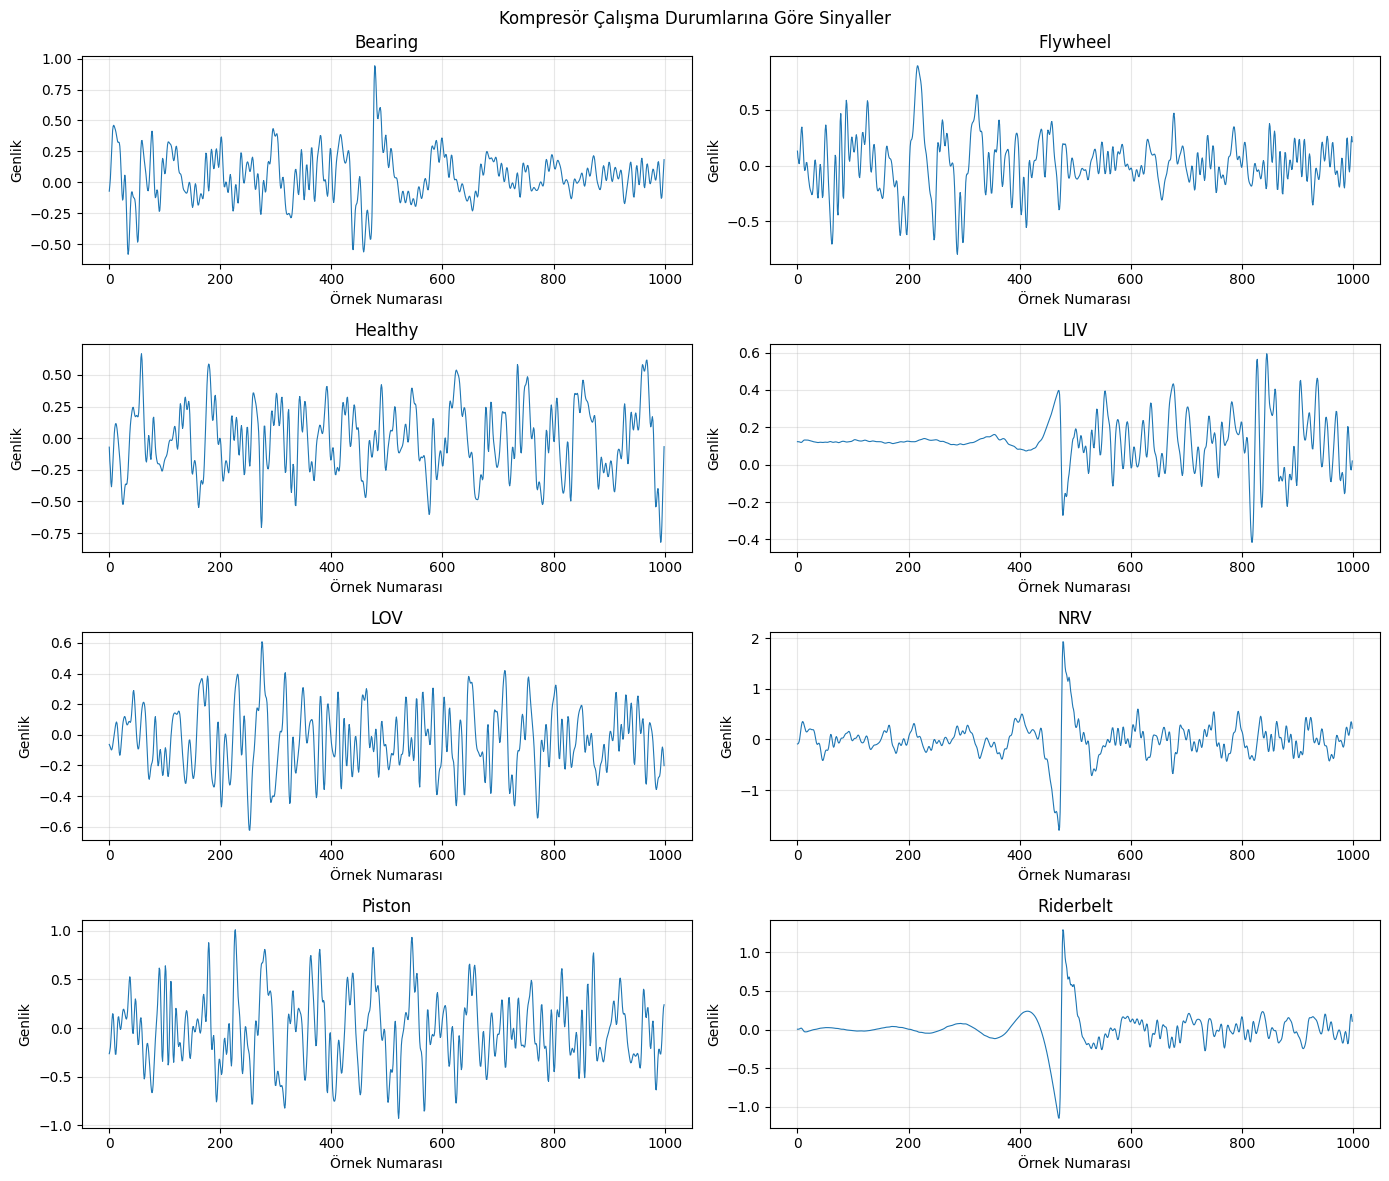

In [4]:
# 2. KEŞİFSEL VERİ ANALİZİ (EDA)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# DAT dosyalarını okuma
def sinyal_oku(dosya_yolu):
    sinyal = np.loadtxt(dosya_yolu, delimiter=",")
    return np.asarray(sinyal).flatten()

# Her dosyanın örnek sayısını belirleme
veri_tablosu["Ornek_Sayisi"] = veri_tablosu["Dosya_Yolu"].apply(
    lambda yol: len(sinyal_oku(yol))
)

print("KAYIT UZUNLUKLARI")
print(veri_tablosu["Ornek_Sayisi"].describe())

# Her sınıftan bir kayıt seçme
ornekler = (
    veri_tablosu
    .sort_values("Dosya")
    .groupby("Ariza_Turu")
    .first()
)

# Sinyalleri görselleştirme
fig, axes = plt.subplots(4, 2, figsize=(14, 12))

for ax, (ariza_turu, satir) in zip(axes.flat, ornekler.iterrows()):

    sinyal = sinyal_oku(satir["Dosya_Yolu"])

    ax.plot(sinyal[:1000], linewidth=0.8)

    ax.set_title(ariza_turu)
    ax.set_xlabel("Örnek Numarası")
    ax.set_ylabel("Genlik")
    ax.grid(alpha=0.3)

plt.suptitle("Kompresör Çalışma Durumlarına Göre Sinyaller")
plt.tight_layout()
plt.show()

In [5]:
# 3. SİNYAL İŞLEME VE ÖZELLİK ÇIKARIMI

import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis

# 3.1. Sinyal özelliklerini hesaplama
def ozellik_cikar(sinyal):

    sinyal = np.asarray(sinyal, dtype=float).flatten()

    # Geçersiz değer kontrolü
    if len(sinyal) < 2 or not np.isfinite(sinyal).all():
        raise ValueError("Sinyalde eksik veya geçersiz değer var.")

    # Zaman alanı özellikleri
    ortalama = np.mean(sinyal)
    standart_sapma = np.std(sinyal)
    rms = np.sqrt(np.mean(sinyal ** 2))
    tepe_deger = np.max(np.abs(sinyal))

    crest_factor = tepe_deger / rms if rms > 0 else 0

    # Frekans alanı özellikleri
    spektrum = np.abs(np.fft.rfft(sinyal - ortalama))
    frekanslar = np.fft.rfftfreq(len(sinyal), d=1)

    toplam_genlik = np.sum(spektrum)

    if toplam_genlik > 0:
        spektral_merkez = np.sum(
            frekanslar * spektrum
        ) / toplam_genlik

        baskin_frekans = frekanslar[np.argmax(spektrum)]
    else:
        spektral_merkez = 0
        baskin_frekans = 0

    return {
        "Ortalama": ortalama,
        "Standart_Sapma": standart_sapma,
        "RMS": rms,
        "Tepe_Deger": tepe_deger,
        "Crest_Factor": crest_factor,
        "Skewness": skew(sinyal),
        "Kurtosis": kurtosis(sinyal),
        "Spektral_Merkez": spektral_merkez,
        "Baskin_Frekans": baskin_frekans
    }


# 3.2. Bütün kayıtların özelliklerini çıkarma
ozellikler = []

for _, satir in veri_tablosu.iterrows():

    sinyal = sinyal_oku(satir["Dosya_Yolu"])

    sonuc = ozellik_cikar(sinyal)

    sonuc["Dosya"] = satir["Dosya"]
    sonuc["Dosya_Yolu"] = satir["Dosya_Yolu"]
    sonuc["Ariza_Turu"] = satir["Ariza_Turu"]
    sonuc["Etiket"] = satir["Etiket"]

    ozellikler.append(sonuc)


# 3.3. Özellik tablosunu oluşturma
ozellik_tablosu = pd.DataFrame(ozellikler)

print("Özellik tablosunun boyutu:", ozellik_tablosu.shape)

print("\nİlk 5 kayıt:")
print(ozellik_tablosu.head())

print("\nEksik değer sayıları:")
print(ozellik_tablosu.isna().sum())

# 3.4. Özelliklerin sınıflara göre ortalamaları
sayisal_ozellikler = [
    "Ortalama",
    "Standart_Sapma",
    "RMS",
    "Tepe_Deger",
    "Crest_Factor",
    "Skewness",
    "Kurtosis",
    "Spektral_Merkez",
    "Baskin_Frekans"
]

print("\nArıza türlerine göre ortalama özellikler:")
print(
    ozellik_tablosu.groupby("Ariza_Turu")[
        sayisal_ozellikler
    ].mean().round(4)
)

Özellik tablosunun boyutu: (1800, 13)

İlk 5 kayıt:
   Ortalama  Standart_Sapma       RMS  Tepe_Deger  Crest_Factor  Skewness  \
0  0.018017        0.210429  0.211199      1.3459      6.372651 -0.064404   
1  0.000854        0.192074  0.192076      1.3833      7.201844 -0.033342   
2  0.025639        0.178002  0.179839      1.5990      8.891286 -0.066401   
3  0.048150        0.210901  0.216327      1.3402      6.195246 -0.078929   
4 -0.049693        0.154383  0.162183      1.5738      9.703841  0.090273   

   Kurtosis  Spektral_Merkez  Baskin_Frekans                      Dosya  \
0  2.560419         0.057175         0.00896  preprocess_Reading127.dat   
1  2.823308         0.056800         0.00900  preprocess_Reading221.dat   
2  4.529637         0.054853         0.00896  preprocess_Reading107.dat   
3  2.687215         0.054307         0.00926  preprocess_Reading114.dat   
4  7.181315         0.057398         0.00970   preprocess_Reading19.dat   

                                  

In [6]:
# 4.1. MODEL ÖNCESİ VERİ SETİ KONTROLÜ

import os
import re
import pandas as pd

# Her sınıftaki kayıt uzunlukları
print("ARIZA TÜRLERİNE GÖRE KAYIT UZUNLUKLARI")

print(
    veri_tablosu.groupby("Ariza_Turu")["Ornek_Sayisi"]
    .agg(["count", "min", "max", "mean"])
)

# Dosya isimlerinden kayıt numaralarını çıkarma
def kayit_numarasi(dosya_adi):
    eslesme = re.search(r"Reading(\d+)", dosya_adi)
    return int(eslesme.group(1)) if eslesme else None

veri_tablosu["Kayit_Numarasi"] = veri_tablosu["Dosya"].apply(
    kayit_numarasi
)

print("\nSINIFLARA GÖRE KAYIT NUMARALARI")

print(
    veri_tablosu.groupby("Ariza_Turu")["Kayit_Numarasi"]
    .agg(["min", "max", "nunique"])
)

print("\nTEKRAR EDEN DOSYA İSİMLERİ")

print(
    veri_tablosu.groupby("Dosya")["Ariza_Turu"]
    .nunique()
    .value_counts()
)

ARIZA TÜRLERİNE GÖRE KAYIT UZUNLUKLARI
            count    min    max     mean
Ariza_Turu                              
Bearing       225  50000  50000  50000.0
Flywheel      225  50000  50000  50000.0
Healthy       225  50000  50000  50000.0
LIV           225  50000  50000  50000.0
LOV           225  50000  50000  50000.0
NRV           225  50000  50000  50000.0
Piston        225  50000  50000  50000.0
Riderbelt     225  50000  50000  50000.0

SINIFLARA GÖRE KAYIT NUMARALARI
            min  max  nunique
Ariza_Turu                   
Bearing       1  225      225
Flywheel      1  225      225
Healthy       1  225      225
LIV           1  225      225
LOV           1  225      225
NRV           1  225      225
Piston        1  225      225
Riderbelt     1  225      225

TEKRAR EDEN DOSYA İSİMLERİ
Ariza_Turu
8    225
Name: count, dtype: int64


In [7]:
# 4. VERİ AYRIMI VE XGBOOST MODELİNİN EĞİTİLMESİ

import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier

# 4.1. Giriş ve hedef değişkenleri

ozellik_sutunlari = [
    "Ortalama",
    "Standart_Sapma",
    "RMS",
    "Tepe_Deger",
    "Crest_Factor",
    "Skewness",
    "Kurtosis",
    "Spektral_Merkez",
    "Baskin_Frekans"
]

X = ozellik_tablosu[ozellik_sutunlari]
y = ozellik_tablosu["Etiket"]

# Kayıt numaralarını özellik tablosundaki dosyalardan çıkarma
# Böylece satır sıraları karışsa bile doğru eşleştirme yapılır.
gruplar = (
    ozellik_tablosu["Dosya"]
    .str.extract(r"Reading(\d+)")[0]
    .astype(int)
)

# 4.2. Önce %70 eğitim, %30 geçici veri

ayirici1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, gecici_idx = next(
    ayirici1.split(X, y, groups=gruplar)
)

# 4.3. Geçici veriyi iki eşit parçaya ayırma
# %15 validation + %15 test

ayirici2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_konum, test_konum = next(
    ayirici2.split(
        X.iloc[gecici_idx],
        y.iloc[gecici_idx],
        groups=gruplar.iloc[gecici_idx]
    )
)

val_idx = gecici_idx[val_konum]
test_idx = gecici_idx[test_konum]

# 4.4. Veri kümelerinin oluşturulması

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]
y_test = y.iloc[test_idx]

print("Eğitim kayıt sayısı:", len(X_train))
print("Validation kayıt sayısı:", len(X_val))
print("Test kayıt sayısı:", len(X_test))

# 4.5. Grupların çakışmadığını kontrol etme

train_grup = set(gruplar.iloc[train_idx])
val_grup = set(gruplar.iloc[val_idx])
test_grup = set(gruplar.iloc[test_idx])

print("\nOrtak gruplar:")
print("Train - Validation:", len(train_grup & val_grup))
print("Train - Test:", len(train_grup & test_grup))
print("Validation - Test:", len(val_grup & test_grup))

# 4.6. XGBoost modelinin oluşturulması

model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    random_state=42,
    eval_metric="logloss"
)

# Modelin eğitilmesi
model.fit(X_train, y_train)

# 4.7. Tahminlerin yapılması

y_train_pred = model.predict(X_train)
y_val_pred = model.predict(X_val)
y_test_pred = model.predict(X_test)

# 4.8. Performans karşılaştırması

print("\nMODEL PERFORMANSI")

for ad, gercek, tahmin in [
    ("Eğitim", y_train, y_train_pred),
    ("Validation", y_val, y_val_pred),
    ("Test", y_test, y_test_pred)
]:
    accuracy = accuracy_score(gercek, tahmin)
    f1 = f1_score(gercek, tahmin)

    print(f"\n{ad}")
    print(f"Accuracy: %{accuracy * 100:.2f}")
    print(f"F1-score: %{f1 * 100:.2f}")

print("\nSınıf dağılımları:")
print("Eğitim:", y_train.value_counts().to_dict())
print("Validation:", y_val.value_counts().to_dict())
print("Test:", y_test.value_counts().to_dict())

Eğitim kayıt sayısı: 1256
Validation kayıt sayısı: 272
Test kayıt sayısı: 272

Ortak gruplar:
Train - Validation: 0
Train - Test: 0
Validation - Test: 0

MODEL PERFORMANSI

Eğitim
Accuracy: %98.01
F1-score: %98.86

Validation
Accuracy: %98.90
F1-score: %99.37

Test
Accuracy: %97.06
F1-score: %98.33

Sınıf dağılımları:
Eğitim: {1: 1099, 0: 157}
Validation: {1: 238, 0: 34}
Test: {1: 238, 0: 34}



EĞITIM SINIFLANDIRMA RAPORU
              precision    recall  f1-score   support

 Healthy (0)     0.9231    0.9172    0.9201       157
   Fault (1)     0.9882    0.9891    0.9886      1099

    accuracy                         0.9801      1256
   macro avg     0.9556    0.9531    0.9544      1256
weighted avg     0.9800    0.9801    0.9801      1256

Balanced Accuracy: %95.31

VALIDATION SINIFLANDIRMA RAPORU
              precision    recall  f1-score   support

 Healthy (0)     0.9697    0.9412    0.9552        34
   Fault (1)     0.9916    0.9958    0.9937       238

    accuracy                         0.9890       272
   macro avg     0.9807    0.9685    0.9745       272
weighted avg     0.9889    0.9890    0.9889       272

Balanced Accuracy: %96.85

TEST SINIFLANDIRMA RAPORU
              precision    recall  f1-score   support

 Healthy (0)     0.9062    0.8529    0.8788        34
   Fault (1)     0.9792    0.9874    0.9833       238

    accuracy                         0.97

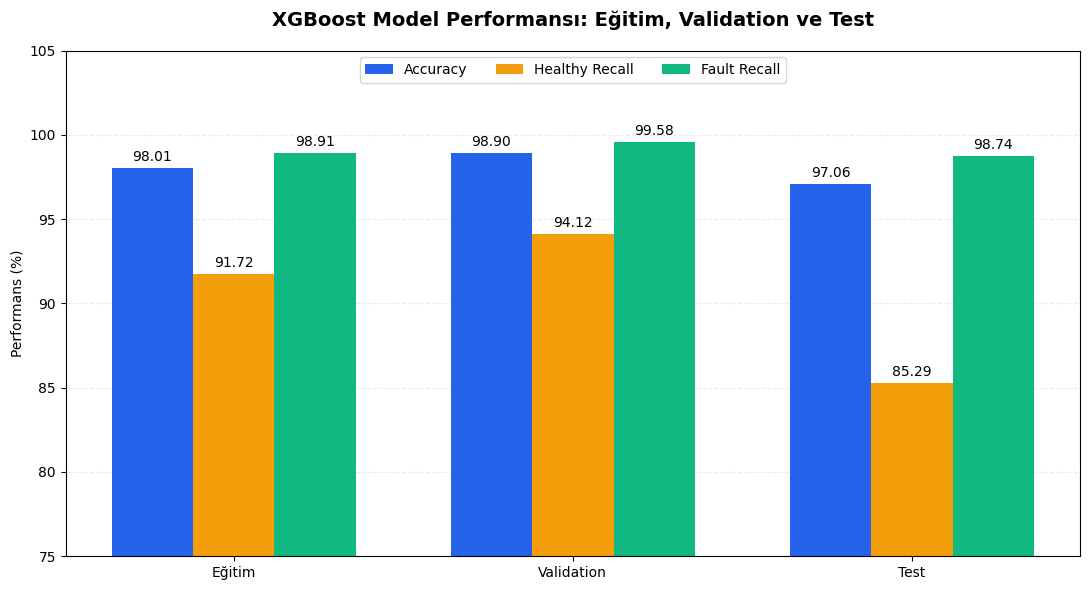

In [8]:
# 5. ADIM - XGBOOST MODELİNİN DEĞERLENDİRİLMESİ

from sklearn.metrics import (
    classification_report,
    balanced_accuracy_score,
    confusion_matrix
)

# 5.1. Eğitim, Validation ve Test Performansları

veri_gruplari = [
    ("Eğitim", y_train, y_train_pred),
    ("Validation", y_val, y_val_pred),
    ("Test", y_test, y_test_pred)
]

for grup_adi, gercek, tahmin in veri_gruplari:

    print(f"\n{'=' * 45}")
    print(f"{grup_adi.upper()} SINIFLANDIRMA RAPORU")
    print(f"{'=' * 45}")

    print(classification_report(
        gercek,
        tahmin,
        labels=[0, 1],
        target_names=["Healthy (0)", "Fault (1)"],
        digits=4,
        zero_division=0
    ))

    balanced_acc = balanced_accuracy_score(gercek, tahmin)

    print(f"Balanced Accuracy: %{balanced_acc * 100:.2f}")

# 5.2. Test Verisinde Sağlıklı ve Arızalı Kayıtların İncelenmesi

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
).ravel()

print("\nTEST VERİSİ - DETAYLI SONUÇLAR")

print("Doğru tahmin edilen sağlıklı kayıt:", tn)
print("Arızalı olarak tahmin edilen sağlıklı kayıt:", fp)
print("Sağlıklı olarak tahmin edilen arızalı kayıt:", fn)
print("Doğru tahmin edilen arızalı kayıt:", tp)

healthy_recall = tn / (tn + fp) if (tn + fp) > 0 else 0
fault_recall = tp / (tp + fn) if (tp + fn) > 0 else 0

print(f"\nHealthy Recall: %{healthy_recall * 100:.2f}")
print(f"Fault Recall: %{fault_recall * 100:.2f}")
# 5.3. MODEL PERFORMANSININ GÖRSELLEŞTİRİLMESİ

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, recall_score

veri_gruplari = [
    ("Eğitim", y_train, y_train_pred),
    ("Validation", y_val, y_val_pred),
    ("Test", y_test, y_test_pred)
]

grup_adlari = []
accuracy_degerleri = []
healthy_recall_degerleri = []
fault_recall_degerleri = []

for ad, gercek, tahmin in veri_gruplari:
    grup_adlari.append(ad)
    accuracy_degerleri.append(
        accuracy_score(gercek, tahmin) * 100
    )
    healthy_recall_degerleri.append(
        recall_score(gercek, tahmin, pos_label=0) * 100
    )
    fault_recall_degerleri.append(
        recall_score(gercek, tahmin, pos_label=1) * 100
    )

x = np.arange(len(grup_adlari))
genislik = 0.24

fig, ax = plt.subplots(figsize=(11, 6))

cubuk1 = ax.bar(
    x - genislik, accuracy_degerleri,
    genislik, label="Accuracy", color="#2563EB"
)

cubuk2 = ax.bar(
    x, healthy_recall_degerleri,
    genislik, label="Healthy Recall", color="#F59E0B"
)

cubuk3 = ax.bar(
    x + genislik, fault_recall_degerleri,
    genislik, label="Fault Recall", color="#10B981"
)

for cubuklar in [cubuk1, cubuk2, cubuk3]:
    ax.bar_label(cubuklar, fmt="%.2f", padding=3, fontsize=10)

ax.set_title(
    "XGBoost Model Performansı: Eğitim, Validation ve Test",
    fontsize=14, fontweight="bold", pad=18
)
ax.set_ylabel("Performans (%)")
ax.set_xticks(x)
ax.set_xticklabels(grup_adlari)
ax.set_ylim(75, 105)
ax.legend(loc="upper center", ncol=3)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("xgboost_model_performansi.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
# 6. TEST KÜMESİNDEN SEÇİLEN KOMPRESÖR KAYDINDA TAHMİN
# 6. ADIM - TEK BİR KOMPRESÖR KAYDININ TAHMİN EDİLMESİ

import pandas as pd

# Test kümesinden bir kayıt seçilmesi
ornek_index = X_test.index[0]

ornek_veri = X_test.loc[[ornek_index]]

# Gerçek sınıf
gercek_etiket = int(y_test.loc[ornek_index])

# Model tahmini
tahmin_etiketi = int(model.predict(ornek_veri)[0])

# Tahmin olasılıkları
olasiliklar = model.predict_proba(ornek_veri)[0]

# Sınıf isimleri
sinif_isimleri = {
    0: "Healthy (Sağlıklı)",
    1: "Fault (Arızalı)"
}

print("6. ADIM - TEK KAYIT TAHMİNİ")
print("-" * 40)

print("Dosya:", ozellik_tablosu.loc[ornek_index, "Dosya"])
print("Gerçek durum:", sinif_isimleri[gercek_etiket])
print("Tahmin edilen durum:", sinif_isimleri[tahmin_etiketi])

print(f"\nSağlıklı sınıf skoru: %{olasiliklar[0] * 100:.2f}")
print(f"Arızalı sınıf skoru: %{olasiliklar[1] * 100:.2f}")

if gercek_etiket == tahmin_etiketi:
    print("\nSonuç: DOĞRU TAHMİN")
else:
    print("\nSonuç: YANLIŞ TAHMİN")

6. ADIM - TEK KAYIT TAHMİNİ
----------------------------------------
Dosya: preprocess_Reading19.dat
Gerçek durum: Fault (Arızalı)
Tahmin edilen durum: Fault (Arızalı)

Sağlıklı sınıf skoru: %0.63
Arızalı sınıf skoru: %99.37

Sonuç: DOĞRU TAHMİN


In [11]:
# 7. ADIM - ÇOK SINIFLI ARIZA ETİKETLERİNİN OLUŞTURULMASI

# 7.1. Sekiz sınıfın tanımlanması

siniflar_multi = {
    "Healthy": 0,
    "Bearing": 1,
    "Flywheel": 2,
    "LIV": 3,
    "LOV": 4,
    "NRV": 5,
    "Piston": 6,
    "Riderbelt": 7
}

# 7.2. Mevcut özellik tablosunun kopyalanması
# Önceki ikili sınıflandırma verilerini değiştirmiyoruz.

ozellik_tablosu_multi = ozellik_tablosu.copy()

# 7.3. Arıza türlerinin sayısal etiketlere dönüştürülmesi

ozellik_tablosu_multi["Etiket_Multi"] = (
    ozellik_tablosu_multi["Ariza_Turu"].map(siniflar_multi)
)

# 7.4. Etiketlerin kontrol edilmesi

print("Toplam kayıt sayısı:", len(ozellik_tablosu_multi))

print("\nÇok sınıflı etiket dağılımı:")

print(
    ozellik_tablosu_multi.groupby(
        ["Ariza_Turu", "Etiket_Multi"]
    ).size()
)

print("\nEksik etiket sayısı:",
      ozellik_tablosu_multi["Etiket_Multi"].isna().sum())

print("\nVeri tablosunun ilk 5 satırı:")

print(
    ozellik_tablosu_multi[
        ["Dosya", "Ariza_Turu", "Etiket", "Etiket_Multi"]
    ].head()
)

Toplam kayıt sayısı: 1800

Çok sınıflı etiket dağılımı:
Ariza_Turu  Etiket_Multi
Bearing     1               225
Flywheel    2               225
Healthy     0               225
LIV         3               225
LOV         4               225
NRV         5               225
Piston      6               225
Riderbelt   7               225
dtype: int64

Eksik etiket sayısı: 0

Veri tablosunun ilk 5 satırı:
                       Dosya Ariza_Turu  Etiket  Etiket_Multi
0  preprocess_Reading127.dat  Riderbelt       1             7
1  preprocess_Reading221.dat  Riderbelt       1             7
2  preprocess_Reading107.dat  Riderbelt       1             7
3  preprocess_Reading114.dat  Riderbelt       1             7
4   preprocess_Reading19.dat  Riderbelt       1             7


In [12]:
# 8. ADIM - ÇOK SINIFLI VERİ AYRIMI

# 8.1. Giriş özelliklerinin belirlenmesi
# Önceki modelimizdeki aynı 9 özelliği kullanıyoruz.

ozellik_sutunlari_multi = list(X_train.columns)

X_multi = ozellik_tablosu_multi[ozellik_sutunlari_multi]
y_multi = ozellik_tablosu_multi["Etiket_Multi"]

# 8.2. Önceki modelin kayıt indekslerini kullanma

X_train_multi = X_multi.loc[X_train.index]
X_val_multi = X_multi.loc[X_val.index]
X_test_multi = X_multi.loc[X_test.index]

y_train_multi = y_multi.loc[X_train.index]
y_val_multi = y_multi.loc[X_val.index]
y_test_multi = y_multi.loc[X_test.index]

# 8.3. Veri gruplarının boyutlarını kontrol etme

print("Eğitim kayıt sayısı:", len(X_train_multi))
print("Validation kayıt sayısı:", len(X_val_multi))
print("Test kayıt sayısı:", len(X_test_multi))

# 8.4. Her veri grubundaki sınıf dağılımı

sinif_adlari_multi = list(siniflar_multi.keys())

print("\nEĞİTİM SINIF DAĞILIMI")
print(y_train_multi.value_counts().sort_index())

print("\nVALIDATION SINIF DAĞILIMI")
print(y_val_multi.value_counts().sort_index())

print("\nTEST SINIF DAĞILIMI")
print(y_test_multi.value_counts().sort_index())

# 8.5. Kayıt indekslerinin çakışmadığını kontrol etme

train_indeksleri = set(X_train_multi.index)
val_indeksleri = set(X_val_multi.index)
test_indeksleri = set(X_test_multi.index)

print("\nORTAK KAYIT İNDEKSLERİ")

print("Eğitim - Validation:",
      len(train_indeksleri & val_indeksleri))

print("Eğitim - Test:",
      len(train_indeksleri & test_indeksleri))

print("Validation - Test:",
      len(val_indeksleri & test_indeksleri))

# 8.6. Reading gruplarının çakışmadığını kontrol etme

kayit_numaralari_multi = (
    ozellik_tablosu_multi["Dosya"]
    .str.extract(r"Reading(\d+)")[0]
    .astype(int)
)

train_gruplari_multi = set(
    kayit_numaralari_multi.loc[X_train_multi.index]
)
val_gruplari_multi = set(
    kayit_numaralari_multi.loc[X_val_multi.index]
)
test_gruplari_multi = set(
    kayit_numaralari_multi.loc[X_test_multi.index]
)

print("\nORTAK READING GRUPLARI")

print("Eğitim - Validation:",
      len(train_gruplari_multi & val_gruplari_multi))

print("Eğitim - Test:",
      len(train_gruplari_multi & test_gruplari_multi))

print("Validation - Test:",
      len(val_gruplari_multi & test_gruplari_multi))

Eğitim kayıt sayısı: 1256
Validation kayıt sayısı: 272
Test kayıt sayısı: 272

EĞİTİM SINIF DAĞILIMI
Etiket_Multi
0    157
1    157
2    157
3    157
4    157
5    157
6    157
7    157
Name: count, dtype: int64

VALIDATION SINIF DAĞILIMI
Etiket_Multi
0    34
1    34
2    34
3    34
4    34
5    34
6    34
7    34
Name: count, dtype: int64

TEST SINIF DAĞILIMI
Etiket_Multi
0    34
1    34
2    34
3    34
4    34
5    34
6    34
7    34
Name: count, dtype: int64

ORTAK KAYIT İNDEKSLERİ
Eğitim - Validation: 0
Eğitim - Test: 0
Validation - Test: 0

ORTAK READING GRUPLARI
Eğitim - Validation: 0
Eğitim - Test: 0
Validation - Test: 0


In [13]:
# 9. ADIM - ÇOK SINIFLI XGBOOST MODELİNİN EĞİTİLMESİ

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

# 9.1. Çok sınıflı modelin oluşturulması

model_multi = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    random_state=42
)

# 9.2. Modelin eğitim verileriyle eğitilmesi

model_multi.fit(X_train_multi, y_train_multi)

# 9.3. Eğitim ve validation tahminleri

y_train_pred_multi = model_multi.predict(X_train_multi)
y_val_pred_multi = model_multi.predict(X_val_multi)

# 9.4. Performans metriklerinin hesaplanması

train_accuracy_multi = accuracy_score(
    y_train_multi, y_train_pred_multi
)

val_accuracy_multi = accuracy_score(
    y_val_multi, y_val_pred_multi
)

train_f1_multi = f1_score(
    y_train_multi, y_train_pred_multi,
    average="macro"
)

val_f1_multi = f1_score(
    y_val_multi, y_val_pred_multi,
    average="macro"
)

# 9.5. Sonuçların yazdırılması

print("ÇOK SINIFLI XGBOOST MODEL PERFORMANSI")
print("-" * 45)

print("\nEĞİTİM")
print(f"Accuracy: %{train_accuracy_multi * 100:.2f}")
print(f"Macro F1-score: %{train_f1_multi * 100:.2f}")

print("\nVALIDATION")
print(f"Accuracy: %{val_accuracy_multi * 100:.2f}")
print(f"Macro F1-score: %{val_f1_multi * 100:.2f}")

print("\nEğitim - Validation Accuracy Farkı:")
print(f"%{(train_accuracy_multi - val_accuracy_multi) * 100:.2f}")

ÇOK SINIFLI XGBOOST MODEL PERFORMANSI
---------------------------------------------

EĞİTİM
Accuracy: %77.47
Macro F1-score: %76.73

VALIDATION
Accuracy: %68.38
Macro F1-score: %66.79

Eğitim - Validation Accuracy Farkı:
%9.09


ÇOK SINIFLI XGBOOST - VALIDATION RAPORU
--------------------------------------------------
              precision    recall  f1-score   support

     Healthy     0.8293    1.0000    0.9067        34
     Bearing     0.5476    0.6765    0.6053        34
    Flywheel     0.6667    0.5294    0.5902        34
         LIV     0.6136    0.7941    0.6923        34
         LOV     0.8182    0.2647    0.4000        34
         NRV     0.5789    0.6471    0.6111        34
      Piston     0.7097    0.6471    0.6769        34
   Riderbelt     0.8158    0.9118    0.8611        34

    accuracy                         0.6838       272
   macro avg     0.6975    0.6838    0.6679       272
weighted avg     0.6975    0.6838    0.6679       272



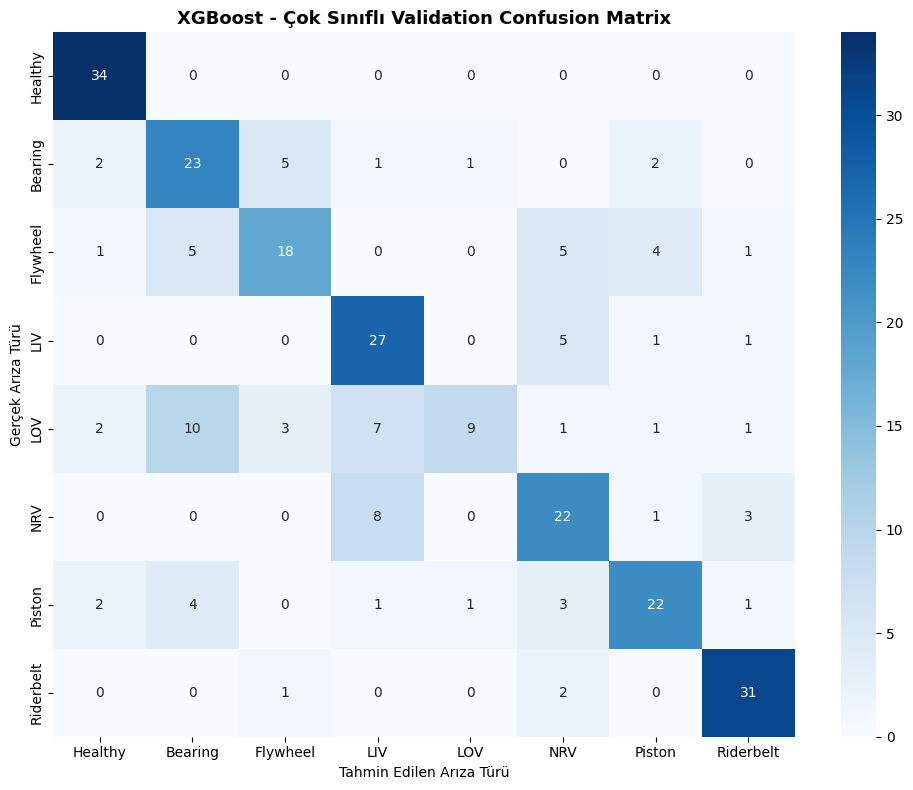

In [14]:

# 10. ADIM - ÇOK SINIFLI MODELİN DEĞERLENDİRİLMESİ

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 10.1. Sınıf isimlerinin tanımlanması

sinif_adlari_multi = [
    "Healthy", "Bearing", "Flywheel", "LIV",
    "LOV", "NRV", "Piston", "Riderbelt"
]

# 10.2. Validation sınıflandırma raporu

print("ÇOK SINIFLI XGBOOST - VALIDATION RAPORU")
print("-" * 50)

print(
    classification_report(
        y_val_multi,
        y_val_pred_multi,
        labels=list(range(8)),
        target_names=sinif_adlari_multi,
        digits=4,
        zero_division=0
    )
)

# 10.3. Confusion Matrix hesaplanması

cm_multi = confusion_matrix(
    y_val_multi,
    y_val_pred_multi,
    labels=list(range(8))
)

# 10.4. Confusion Matrix görselleştirilmesi

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    cm_multi,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sinif_adlari_multi,
    yticklabels=sinif_adlari_multi,
    ax=ax
)

ax.set_title(
    "XGBoost - Çok Sınıflı Validation Confusion Matrix",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Tahmin Edilen Arıza Türü")
ax.set_ylabel("Gerçek Arıza Türü")

plt.tight_layout()
plt.show()

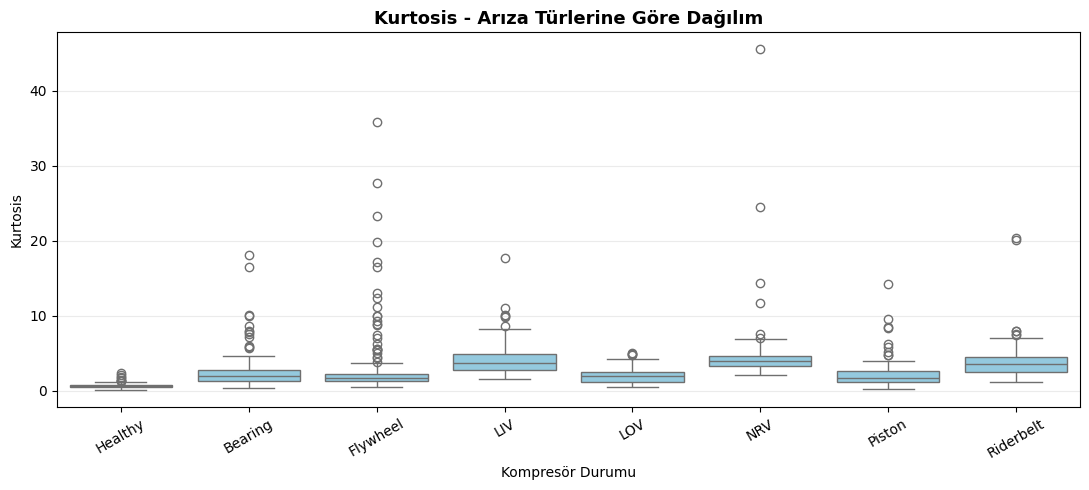

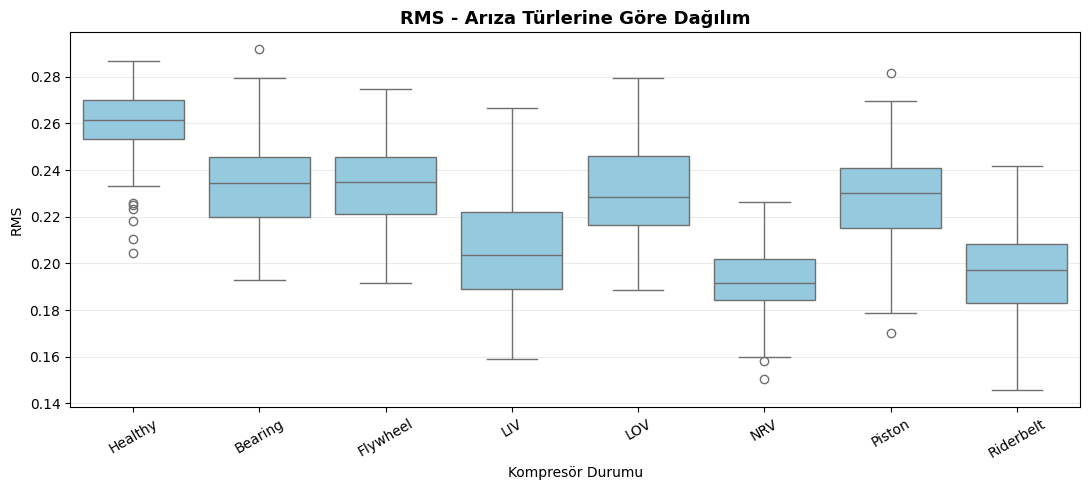

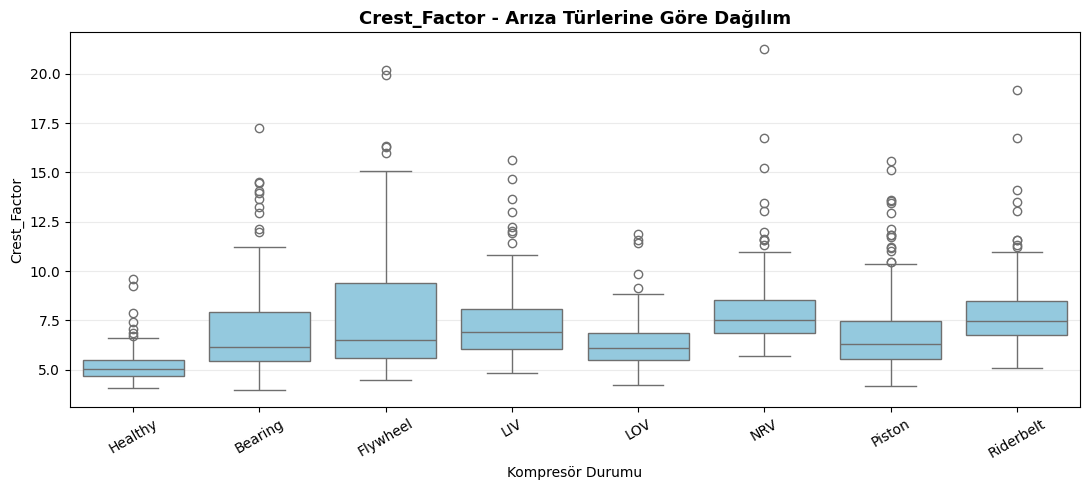

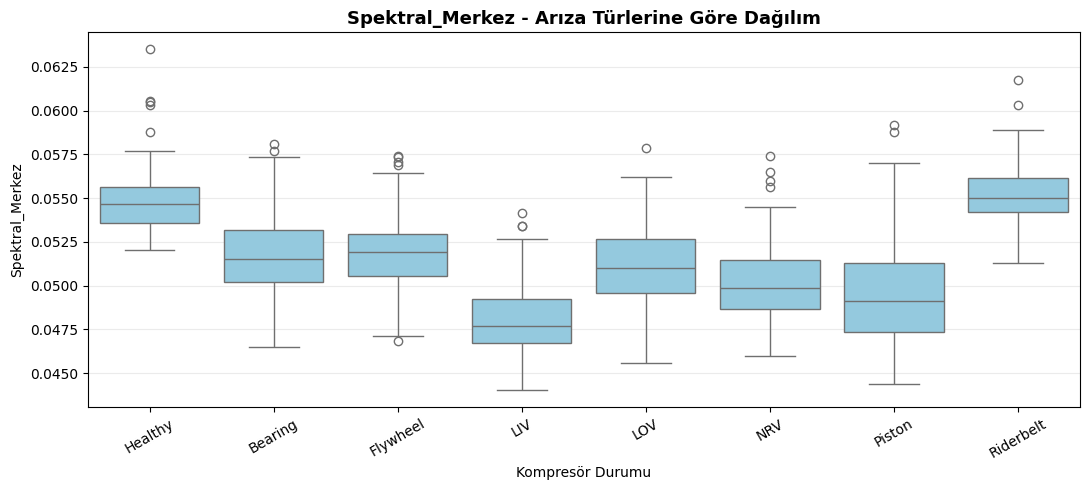

In [15]:
# 11. ADIM - AKUSTİK ÖZELLİKLERİN SINIFLARA GÖRE ANALİZİ

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 11.1. Yalnızca eğitim verilerinin hazırlanması

analiz_tablosu = X_train_multi.copy()

analiz_tablosu["Ariza_Turu"] = (
    y_train_multi.map({
        0: "Healthy",
        1: "Bearing",
        2: "Flywheel",
        3: "LIV",
        4: "LOV",
        5: "NRV",
        6: "Piston",
        7: "Riderbelt"
    })
)

# 11.2. İncelenecek özellikler

incelenecek_ozellikler = [
    "Kurtosis",
    "RMS",
    "Crest_Factor",
    "Spektral_Merkez"
]

sinif_sirasi = [
    "Healthy", "Bearing", "Flywheel", "LIV",
    "LOV", "NRV", "Piston", "Riderbelt"
]

# 11.3. Her özellik için ayrı boxplot

for ozellik in incelenecek_ozellikler:

    plt.figure(figsize=(11, 5))

    sns.boxplot(
        data=analiz_tablosu,
        x="Ariza_Turu",
        y=ozellik,
        order=sinif_sirasi,
        color="skyblue"
    )

    plt.title(
        f"{ozellik} - Arıza Türlerine Göre Dağılım",
        fontsize=13,
        fontweight="bold"
    )

    plt.xlabel("Kompresör Durumu")
    plt.ylabel(ozellik)

    plt.xticks(rotation=30)
    plt.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()

In [16]:

# 12. ADIM - YENİ AKUSTİK ÖZELLİKLERİN ÇIKARILMASI

import numpy as np
import pandas as pd

# 12.1. Yeni özellikleri hesaplayan fonksiyon

def yeni_ozellik_cikar(sinyal):

    # Sinyalin ortalamasını çıkarma
    sinyal = np.asarray(sinyal, dtype=float)
    sinyal = sinyal - np.mean(sinyal)

    # Frekans spektrumu
    fft = np.fft.rfft(sinyal)
    frekans = np.fft.rfftfreq(len(sinyal), d=1.0)

    # Güç spektrumu
    guc = np.abs(fft) ** 2
    toplam_guc = np.sum(guc)

    if toplam_guc == 0:
        return {
            "Spektral_Entropi": 0.0,
            "Dusuk_Bant_Enerjisi": 0.0,
            "Orta_Bant_Enerjisi": 0.0,
            "Yuksek_Bant_Enerjisi": 0.0,
            "Spectral_Rolloff": 0.0
        }

    # 12.2. Spektral entropi (normalize edilmiş)
    p = guc / toplam_guc
    p_pozitif = p[p > 0]

    entropi = -np.sum(p_pozitif * np.log2(p_pozitif))
    entropi = entropi / np.log2(len(p))

    # 12.3. Frekans bantlarının enerji oranları
    # Frekanslar çevrim/örnek cinsindedir.

    dusuk = np.sum(guc[frekans < 0.10]) / toplam_guc

    orta = np.sum(
        guc[(frekans >= 0.10) & (frekans < 0.25)]
    ) / toplam_guc

    yuksek = np.sum(
        guc[frekans >= 0.25]
    ) / toplam_guc

    # 12.4. Spectral Rolloff (%85 güç eşiği)
    birikimli_guc = np.cumsum(guc)
    rolloff_indeksi = np.searchsorted(
        birikimli_guc, 0.85 * toplam_guc
    )
    rolloff = frekans[rolloff_indeksi]

    return {
        "Spektral_Entropi": entropi,
        "Dusuk_Bant_Enerjisi": dusuk,
        "Orta_Bant_Enerjisi": orta,
        "Yuksek_Bant_Enerjisi": yuksek,
        "Spectral_Rolloff": rolloff
    }


# 12.5. Mevcut tablonun kopyalanması

ozellik_tablosu_14 = ozellik_tablosu_multi.copy()

# 12.6. Her ses kaydından yeni özelliklerin çıkarılması

yeni_ozellik_listesi = []

for dosya_yolu in ozellik_tablosu_14["Dosya_Yolu"]:

    sinyal = sinyal_oku(dosya_yolu)

    ozellikler = yeni_ozellik_cikar(sinyal)

    yeni_ozellik_listesi.append(ozellikler)

# 12.7. Yeni özelliklerin tabloya eklenmesi

yeni_ozellik_df = pd.DataFrame(
    yeni_ozellik_listesi,
    index=ozellik_tablosu_14.index
)

ozellik_tablosu_14 = pd.concat(
    [ozellik_tablosu_14, yeni_ozellik_df],
    axis=1
)

# 12.8. Sonuçların kontrol edilmesi

yeni_sutunlar = list(yeni_ozellik_df.columns)

print("Toplam kayıt:", len(ozellik_tablosu_14))
print("Yeni özellik sayısı:", len(yeni_sutunlar))
print("Toplam model özelliği:", len(X_train_multi.columns) + len(yeni_sutunlar))

print("\nEksik değer sayısı:")
print(ozellik_tablosu_14[yeni_sutunlar].isna().sum())

print("\nSonsuz değer sayısı:")
print(np.isinf(ozellik_tablosu_14[yeni_sutunlar]).sum())

print("\nYeni özelliklerin ilk 5 satırı:")
print(ozellik_tablosu_14[yeni_sutunlar].head())

print("\nBant enerji oranlarının toplamı:")
bant_toplami = ozellik_tablosu_14[
    ["Dusuk_Bant_Enerjisi",
     "Orta_Bant_Enerjisi",
     "Yuksek_Bant_Enerjisi"]
].sum(axis=1)

print(bant_toplami.describe())


Toplam kayıt: 1800
Yeni özellik sayısı: 5
Toplam model özelliği: 14

Eksik değer sayısı:
Spektral_Entropi        0
Dusuk_Bant_Enerjisi     0
Orta_Bant_Enerjisi      0
Yuksek_Bant_Enerjisi    0
Spectral_Rolloff        0
dtype: int64

Sonsuz değer sayısı:
Spektral_Entropi        0
Dusuk_Bant_Enerjisi     0
Orta_Bant_Enerjisi      0
Yuksek_Bant_Enerjisi    0
Spectral_Rolloff        0
dtype: int64

Yeni özelliklerin ilk 5 satırı:
   Spektral_Entropi  Dusuk_Bant_Enerjisi  Orta_Bant_Enerjisi  \
0          0.732637             0.948100            0.051877   
1          0.737095             0.941994            0.058003   
2          0.722190             0.953413            0.046585   
3          0.713423             0.954406            0.045592   
4          0.755186             0.946621            0.053372   

   Yuksek_Bant_Enerjisi  Spectral_Rolloff  
0              0.000023           0.06750  
1              0.000003           0.07226  
2              0.000002           0.06544  
3        

In [17]:

# 13. ADIM - 14 ÖZELLİKLİ XGBOOST MODELİNİN EĞİTİLMESİ

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

# 13.1. Yeni özellik sütunlarının belirlenmesi

yeni_sutunlar = [
    "Spektral_Entropi",
    "Dusuk_Bant_Enerjisi",
    "Orta_Bant_Enerjisi",
    "Yuksek_Bant_Enerjisi",
    "Spectral_Rolloff"
]

tum_ozellikler_14 = list(X_train_multi.columns) + yeni_sutunlar

# 13.2. Mevcut veri ayrımının korunması

X_train_14 = ozellik_tablosu_14.loc[
    X_train_multi.index, tum_ozellikler_14
]

X_val_14 = ozellik_tablosu_14.loc[
    X_val_multi.index, tum_ozellikler_14
]

# 13.3. Yeni modelin oluşturulması

model_multi_14 = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    random_state=42
)

# 13.4. Modelin eğitilmesi

model_multi_14.fit(X_train_14, y_train_multi)

# 13.5. Eğitim ve validation tahminleri

y_train_pred_14 = model_multi_14.predict(X_train_14)
y_val_pred_14 = model_multi_14.predict(X_val_14)

# 13.6. Performansların hesaplanması

train_acc_14 = accuracy_score(y_train_multi, y_train_pred_14)
val_acc_14 = accuracy_score(y_val_multi, y_val_pred_14)

train_f1_14 = f1_score(
    y_train_multi, y_train_pred_14, average="macro"
)

val_f1_14 = f1_score(
    y_val_multi, y_val_pred_14, average="macro"
)

# 13.7. Önceki modelle karşılaştırma

print("9 VE 14 ÖZELLİKLİ XGBOOST KARŞILAŞTIRMASI")
print("-" * 55)

print(f"{'Metrik':<25} {'9 Özellik':>12} {'14 Özellik':>12}")

print(
    f"{'Eğitim Accuracy':<25}"
    f"{train_accuracy_multi * 100:>11.2f}%"
    f"{train_acc_14 * 100:>11.2f}%"
)

print(
    f"{'Validation Accuracy':<25}"
    f"{val_accuracy_multi * 100:>11.2f}%"
    f"{val_acc_14 * 100:>11.2f}%"
)

print(
    f"{'Eğitim Macro F1':<25}"
    f"{train_f1_multi * 100:>11.2f}%"
    f"{train_f1_14 * 100:>11.2f}%"
)

print(
    f"{'Validation Macro F1':<25}"
    f"{val_f1_multi * 100:>11.2f}%"
    f"{val_f1_14 * 100:>11.2f}%"
)

print("\n14 ÖZELLİKLİ MODEL - OVERFITTING KONTROLÜ")

print(
    f"Eğitim - Validation Accuracy Farkı: "
    f"{(train_acc_14 - val_acc_14) * 100:.2f} yüzde puan"
)


9 VE 14 ÖZELLİKLİ XGBOOST KARŞILAŞTIRMASI
-------------------------------------------------------
Metrik                       9 Özellik   14 Özellik
Eğitim Accuracy                77.47%      95.30%
Validation Accuracy            68.38%      85.66%
Eğitim Macro F1                76.73%      95.30%
Validation Macro F1            66.79%      85.56%

14 ÖZELLİKLİ MODEL - OVERFITTING KONTROLÜ
Eğitim - Validation Accuracy Farkı: 9.64 yüzde puan


14 ÖZELLİKLİ XGBOOST - VALIDATION RAPORU
-------------------------------------------------------
              precision    recall  f1-score   support

     Healthy     0.9714    1.0000    0.9855        34
     Bearing     0.7742    0.7059    0.7385        34
    Flywheel     0.7879    0.7647    0.7761        34
         LIV     0.8889    0.9412    0.9143        34
         LOV     0.8788    0.8529    0.8657        34
         NRV     0.7895    0.8824    0.8333        34
      Piston     0.8182    0.7941    0.8060        34
   Riderbelt     0.9394    0.9118    0.9254        34

    accuracy                         0.8566       272
   macro avg     0.8560    0.8566    0.8556       272
weighted avg     0.8560    0.8566    0.8556       272



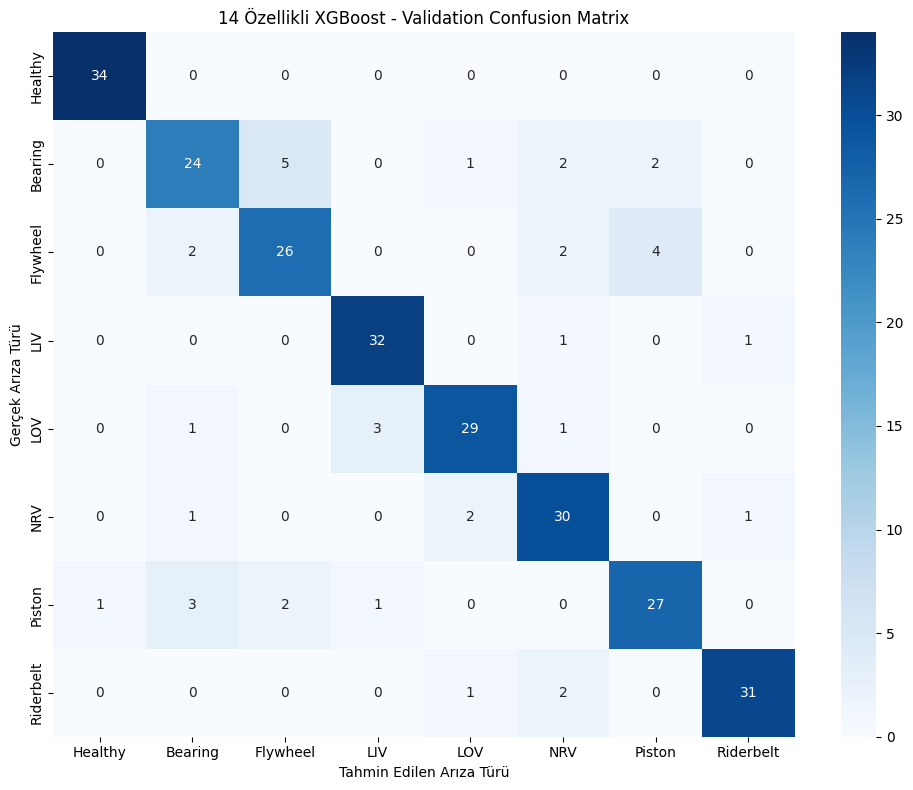


9 VE 14 ÖZELLİKLİ MODELLERİN KARŞILAŞTIRILMASI
Arıza Türü  Recall (9 Özellik) %  Recall (14 Özellik) %  F1 (9 Özellik) %  F1 (14 Özellik) %  Recall Değişimi (puan)
   Healthy                100.00                 100.00             90.67              98.55                    0.00
   Bearing                 67.65                  70.59             60.53              73.85                    2.94
  Flywheel                 52.94                  76.47             59.02              77.61                   23.53
       LIV                 79.41                  94.12             69.23              91.43                   14.71
       LOV                 26.47                  85.29             40.00              86.57                   58.82
       NRV                 64.71                  88.24             61.11              83.33                   23.53
    Piston                 64.71                  79.41             67.69              80.60                   14.71
 Riderbelt      

In [18]:

# 14. ADIM - 14 ÖZELLİKLİ MODELİN DEĞERLENDİRİLMESİ

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

# 14.1. Sınıf isimlerinin tanımlanması

sinif_adlari_multi = [
    "Healthy", "Bearing", "Flywheel", "LIV",
    "LOV", "NRV", "Piston", "Riderbelt"
]

# 14.2. Yeni modelin validation sınıflandırma raporu

print("14 ÖZELLİKLİ XGBOOST - VALIDATION RAPORU")
print("-" * 55)

print(classification_report(
    y_val_multi,
    y_val_pred_14,
    labels=list(range(8)),
    target_names=sinif_adlari_multi,
    digits=4,
    zero_division=0
))

# 14.3. Confusion Matrix oluşturulması

cm_14 = confusion_matrix(
    y_val_multi,
    y_val_pred_14,
    labels=list(range(8))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_14,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sinif_adlari_multi,
    yticklabels=sinif_adlari_multi
)

plt.title("14 Özellikli XGBoost - Validation Confusion Matrix")
plt.xlabel("Tahmin Edilen Arıza Türü")
plt.ylabel("Gerçek Arıza Türü")

plt.tight_layout()
plt.show()

# 14.4. Eski ve yeni modellerin sınıf bazında karşılaştırılması

_, recall_9, f1_9, _ = precision_recall_fscore_support(
    y_val_multi,
    y_val_pred_multi,
    labels=list(range(8)),
    zero_division=0
)

_, recall_14, f1_14, _ = precision_recall_fscore_support(
    y_val_multi,
    y_val_pred_14,
    labels=list(range(8)),
    zero_division=0
)

karsilastirma_14 = pd.DataFrame({
    "Arıza Türü": sinif_adlari_multi,
    "Recall (9 Özellik) %": recall_9 * 100,
    "Recall (14 Özellik) %": recall_14 * 100,
    "F1 (9 Özellik) %": f1_9 * 100,
    "F1 (14 Özellik) %": f1_14 * 100
})

karsilastirma_14["Recall Değişimi (puan)"] = (
    karsilastirma_14["Recall (14 Özellik) %"]
    - karsilastirma_14["Recall (9 Özellik) %"]
)

print("\n9 VE 14 ÖZELLİKLİ MODELLERİN KARŞILAŞTIRILMASI")
print(karsilastirma_14.round(2).to_string(index=False))


14 ÖZELLİKLİ XGBOOST - ÖZELLİK ÖNEM SIRALAMASI
-------------------------------------------------------
             Özellik  Önem Skoru
  Orta_Bant_Enerjisi    0.174064
    Spectral_Rolloff    0.138954
            Kurtosis    0.124280
    Spektral_Entropi    0.107501
                 RMS    0.100237
 Dusuk_Bant_Enerjisi    0.079852
     Spektral_Merkez    0.059040
            Skewness    0.045845
      Standart_Sapma    0.044537
      Baskin_Frekans    0.044107
            Ortalama    0.029836
          Tepe_Deger    0.024684
        Crest_Factor    0.016331
Yuksek_Bant_Enerjisi    0.010732


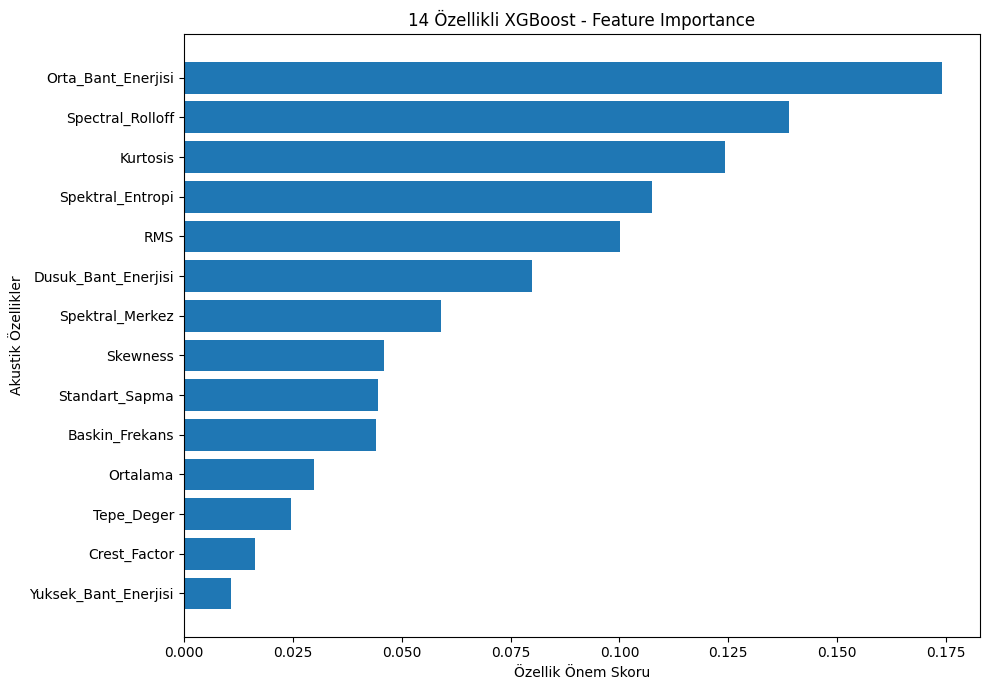

In [19]:

# 15. ADIM - ÖZELLİK ÖNEM ANALİZİ

import pandas as pd
import matplotlib.pyplot as plt

# 15.1. Modelden özellik önemlerinin alınması

onem_degerleri = model_multi_14.feature_importances_

# 15.2. Özellik önem tablosunun oluşturulması

ozellik_onem_tablosu = pd.DataFrame({
    "Özellik": X_train_14.columns,
    "Önem Skoru": onem_degerleri
})

# Önem skoruna göre büyükten küçüğe sıralama
ozellik_onem_tablosu = ozellik_onem_tablosu.sort_values(
    by="Önem Skoru",
    ascending=False
)

print("14 ÖZELLİKLİ XGBOOST - ÖZELLİK ÖNEM SIRALAMASI")
print("-" * 55)
print(ozellik_onem_tablosu.to_string(index=False))

# 15.3. Özellik önem grafiği

plt.figure(figsize=(10, 7))

plt.barh(
    ozellik_onem_tablosu["Özellik"],
    ozellik_onem_tablosu["Önem Skoru"]
)

plt.xlabel("Özellik Önem Skoru")
plt.ylabel("Akustik Özellikler")
plt.title("14 Özellikli XGBoost - Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()



In [20]:

# 16. ADIM - SON MODEL DENEMESİ: EN ÖNEMLİ 10 ÖZELLİK

import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

# 16.1. En önemli 10 özelliğin seçilmesi

en_iyi_10_ozellik = ozellik_onem_tablosu.head(10)["Özellik"].tolist()

print("SEÇİLEN 10 ÖZELLİK:")
for i, ozellik in enumerate(en_iyi_10_ozellik, start=1):
    print(f"{i}. {ozellik}")

# 16.2. Eğitim ve validation verilerinin hazırlanması

X_train_10 = X_train_14[en_iyi_10_ozellik].copy()
X_val_10 = X_val_14[en_iyi_10_ozellik].copy()

# 16.3. Yeni XGBoost modelinin oluşturulması

model_multi_10 = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    random_state=42
)

# 16.4. Modelin eğitilmesi

model_multi_10.fit(X_train_10, y_train_multi)

# 16.5. Tahminlerin yapılması

y_train_pred_10 = model_multi_10.predict(X_train_10)
y_val_pred_10 = model_multi_10.predict(X_val_10)

# 16.6. Performans metriklerinin hesaplanması

train_acc_10 = accuracy_score(y_train_multi, y_train_pred_10)
val_acc_10 = accuracy_score(y_val_multi, y_val_pred_10)

train_f1_10 = f1_score(
    y_train_multi, y_train_pred_10, average="macro"
)

val_f1_10 = f1_score(
    y_val_multi, y_val_pred_10, average="macro"
)

# 16.7. Üç modelin karşılaştırılması

son_karsilastirma = pd.DataFrame({
    "Model": ["9 Özellik", "14 Özellik", "10 Özellik"],
    "Eğitim Accuracy (%)": [
        train_accuracy_multi * 100,
        train_acc_14 * 100,
        train_acc_10 * 100
    ],
    "Validation Accuracy (%)": [
        val_accuracy_multi * 100,
        val_acc_14 * 100,
        val_acc_10 * 100
    ],
    "Eğitim Macro F1 (%)": [
        train_f1_multi * 100,
        train_f1_14 * 100,
        train_f1_10 * 100
    ],
    "Validation Macro F1 (%)": [
        val_f1_multi * 100,
        val_f1_14 * 100,
        val_f1_10 * 100
    ]
})

son_karsilastirma["Accuracy Farkı (puan)"] = (
    son_karsilastirma["Eğitim Accuracy (%)"]
    - son_karsilastirma["Validation Accuracy (%)"]
)

print("\nSON MODEL KARŞILAŞTIRMASI")
print(son_karsilastirma.round(2).to_string(index=False))

# 16.8. Validation Macro F1'e göre modelin seçilmesi

en_iyi_model = son_karsilastirma.loc[
    son_karsilastirma["Validation Macro F1 (%)"].idxmax()
]

print("\nVALIDATION MACRO F1'E GÖRE EN İYİ MODEL:")
print(en_iyi_model["Model"])
print(
    f"Validation Macro F1: "
    f"%{en_iyi_model['Validation Macro F1 (%)']:.2f}"
)


SEÇİLEN 10 ÖZELLİK:
1. Orta_Bant_Enerjisi
2. Spectral_Rolloff
3. Kurtosis
4. Spektral_Entropi
5. RMS
6. Dusuk_Bant_Enerjisi
7. Spektral_Merkez
8. Skewness
9. Standart_Sapma
10. Baskin_Frekans

SON MODEL KARŞILAŞTIRMASI
     Model  Eğitim Accuracy (%)  Validation Accuracy (%)  Eğitim Macro F1 (%)  Validation Macro F1 (%)  Accuracy Farkı (puan)
 9 Özellik                77.47                    68.38                76.73                    66.79                   9.09
14 Özellik                95.30                    85.66                95.30                    85.56                   9.64
10 Özellik                94.67                    85.29                94.66                    85.19                   9.37

VALIDATION MACRO F1'E GÖRE EN İYİ MODEL:
14 Özellik
Validation Macro F1: %85.56


In [21]:

# 17. ADIM - DÖRT YENİ AKUSTİK ÖZELLİĞİN ÇIKARILMASI

import numpy as np
import pandas as pd

# 17.1. Yeni özellikleri hesaplayan fonksiyon

def dort_yeni_ozellik_cikar(sinyal):

    sinyal = np.asarray(sinyal, dtype=float)

    # Sinyalin ortalamasını çıkarma
    sinyal = sinyal - np.mean(sinyal)

    # Frekans spektrumu
    fft = np.fft.rfft(sinyal)
    frekans = np.fft.rfftfreq(len(sinyal), d=1.0)

    # Güç spektrumu
    guc = np.abs(fft) ** 2
    toplam_guc = np.sum(guc)

    # 1. Spectral Flatness
    if toplam_guc > 0:
        pozitif_guc = guc + 1e-12

        geometrik_ortalama = np.exp(
            np.mean(np.log(pozitif_guc))
        )

        aritmetik_ortalama = np.mean(pozitif_guc)

        spectral_flatness = (
            geometrik_ortalama / aritmetik_ortalama
        )

        # 2. Spectral Bandwidth
        spektral_merkez = np.sum(
            frekans * guc
        ) / toplam_guc

        spectral_bandwidth = np.sqrt(
            np.sum(
                ((frekans - spektral_merkez) ** 2) * guc
            ) / toplam_guc
        )

    else:
        spectral_flatness = 0.0
        spectral_bandwidth = 0.0

    # 3. Zero Crossing Rate
    # Ardışık örneklerde işaret değişimi
    zero_crossing_rate = np.mean(
        np.signbit(sinyal[1:]) != np.signbit(sinyal[:-1])
    )

    # 4. Impulse Factor
    ortalama_mutlak = np.mean(np.abs(sinyal))

    if ortalama_mutlak > 0:
        impulse_factor = (
            np.max(np.abs(sinyal)) / ortalama_mutlak
        )
    else:
        impulse_factor = 0.0

    return {
        "Spectral_Flatness": spectral_flatness,
        "Spectral_Bandwidth": spectral_bandwidth,
        "Zero_Crossing_Rate": zero_crossing_rate,
        "Impulse_Factor": impulse_factor
    }


# 17.2. Mevcut 14 özellikli tablonun korunması

ozellik_tablosu_18 = ozellik_tablosu_14.copy()

# 17.3. Yeni özelliklerin bütün kayıtlardan çıkarılması

yeni_ozellikler_18 = []

for dosya_yolu in ozellik_tablosu_18["Dosya_Yolu"]:

    sinyal = sinyal_oku(dosya_yolu)

    ozellikler = dort_yeni_ozellik_cikar(sinyal)

    yeni_ozellikler_18.append(ozellikler)


# 17.4. Yeni özelliklerin tabloya eklenmesi

yeni_ozellik_df_18 = pd.DataFrame(
    yeni_ozellikler_18,
    index=ozellik_tablosu_18.index
)

ozellik_tablosu_18 = pd.concat(
    [ozellik_tablosu_18, yeni_ozellik_df_18],
    axis=1
)


# 17.5. Sonuçların kontrol edilmesi

yeni_sutunlar_18 = list(yeni_ozellik_df_18.columns)

print("Toplam kayıt:", len(ozellik_tablosu_18))
print("Yeni eklenen özellik sayısı:", len(yeni_sutunlar_18))
print("Toplam model özelliği:", len(X_train_14.columns) + len(yeni_sutunlar_18))

print("\nEksik değer sayısı:")
print(ozellik_tablosu_18[yeni_sutunlar_18].isna().sum())

print("\nSonsuz değer sayısı:")
print(np.isinf(ozellik_tablosu_18[yeni_sutunlar_18]).sum())

print("\nYeni özelliklerin ilk 5 satırı:")
print(ozellik_tablosu_18[yeni_sutunlar_18].head())

print("\nYeni özelliklerin istatistiksel özeti:")
print(ozellik_tablosu_18[yeni_sutunlar_18].describe())


Toplam kayıt: 1800
Yeni eklenen özellik sayısı: 4
Toplam model özelliği: 18

Eksik değer sayısı:
Spectral_Flatness     0
Spectral_Bandwidth    0
Zero_Crossing_Rate    0
Impulse_Factor        0
dtype: int64

Sonsuz değer sayısı:
Spectral_Flatness     0
Spectral_Bandwidth    0
Zero_Crossing_Rate    0
Impulse_Factor        0
dtype: int64

Yeni özelliklerin ilk 5 satırı:
   Spectral_Flatness  Spectral_Bandwidth  Zero_Crossing_Rate  Impulse_Factor
0           0.001060            0.028965            0.082342        8.685836
1           0.000360            0.029892            0.085222        9.807444
2           0.000232            0.028100            0.079402       12.423151
3           0.000204            0.027549            0.078182        9.033465
4           0.000567            0.029952            0.088942       15.069151

Yeni özelliklerin istatistiksel özeti:
       Spectral_Flatness  Spectral_Bandwidth  Zero_Crossing_Rate  \
count        1800.000000         1800.000000         1800.00

In [22]:

# 18. ADIM - 18 ÖZELLİKLİ XGBOOST MODELİ

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# 18.1. Kullanılacak özelliklerin belirlenmesi

tum_ozellikler_18 = list(X_train_14.columns) + yeni_sutunlar_18

# 18.2. Eğitim ve validation verilerinin hazırlanması

X_train_18 = ozellik_tablosu_18.loc[
    X_train_multi.index, tum_ozellikler_18
].copy()

X_val_18 = ozellik_tablosu_18.loc[
    X_val_multi.index, tum_ozellikler_18
].copy()

# 18.3. Yeni modelin oluşturulması

model_multi_18 = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    random_state=42
)

# 18.4. Modelin eğitilmesi

model_multi_18.fit(X_train_18, y_train_multi)

# 18.5. Tahminlerin yapılması

y_train_pred_18 = model_multi_18.predict(X_train_18)
y_val_pred_18 = model_multi_18.predict(X_val_18)

# 18.6. Performans metriklerinin hesaplanması

train_acc_18 = accuracy_score(y_train_multi, y_train_pred_18)
val_acc_18 = accuracy_score(y_val_multi, y_val_pred_18)

train_f1_18 = f1_score(
    y_train_multi,
    y_train_pred_18,
    average="macro"
)

val_f1_18 = f1_score(
    y_val_multi,
    y_val_pred_18,
    average="macro"
)

# 18.7. Önceki modellerle karşılaştırma

son_model_karsilastirma = pd.DataFrame({
    "Model": [
        "9 Özellik",
        "10 Özellik",
        "14 Özellik",
        "18 Özellik"
    ],
    "Eğitim Accuracy (%)": [
        train_accuracy_multi * 100,
        train_acc_10 * 100,
        train_acc_14 * 100,
        train_acc_18 * 100
    ],
    "Validation Accuracy (%)": [
        val_accuracy_multi * 100,
        val_acc_10 * 100,
        val_acc_14 * 100,
        val_acc_18 * 100
    ],
    "Eğitim Macro F1 (%)": [
        train_f1_multi * 100,
        train_f1_10 * 100,
        train_f1_14 * 100,
        train_f1_18 * 100
    ],
    "Validation Macro F1 (%)": [
        val_f1_multi * 100,
        val_f1_10 * 100,
        val_f1_14 * 100,
        val_f1_18 * 100
    ]
})

son_model_karsilastirma["Accuracy Farkı (puan)"] = (
    son_model_karsilastirma["Eğitim Accuracy (%)"]
    - son_model_karsilastirma["Validation Accuracy (%)"]
)

print("SON MODEL KARŞILAŞTIRMASI")
print("-" * 70)

print(
    son_model_karsilastirma.round(2).to_string(index=False)
)

# 18.8. Validation Macro F1'e göre model seçimi

en_iyi_sonuc = son_model_karsilastirma.loc[
    son_model_karsilastirma[
        "Validation Macro F1 (%)"
    ].idxmax()
]

print("\nVALIDATION MACRO F1'E GÖRE EN İYİ MODEL:")
print(en_iyi_sonuc["Model"])

print(
    f"Validation Macro F1: "
    f"%{en_iyi_sonuc['Validation Macro F1 (%)']:.2f}"
)


SON MODEL KARŞILAŞTIRMASI
----------------------------------------------------------------------
     Model  Eğitim Accuracy (%)  Validation Accuracy (%)  Eğitim Macro F1 (%)  Validation Macro F1 (%)  Accuracy Farkı (puan)
 9 Özellik                77.47                    68.38                76.73                    66.79                   9.09
10 Özellik                94.67                    85.29                94.66                    85.19                   9.37
14 Özellik                95.30                    85.66                95.30                    85.56                   9.64
18 Özellik                95.86                    85.66                95.86                    85.50                  10.20

VALIDATION MACRO F1'E GÖRE EN İYİ MODEL:
14 Özellik
Validation Macro F1: %85.56


14 ÖZELLİKLİ XGBOOST - TEST SONUÇLARI
-------------------------------------------------------
Test Accuracy:        %90.44
Test Macro Precision: %90.72
Test Macro Recall:    %90.44
Test Macro F1:        %90.47

VALIDATION - TEST KARŞILAŞTIRMASI
  Metrik  Validation (%)  Test (%)  Fark (Test - Validation)
Accuracy           85.66     90.44                      4.78
Macro F1           85.56     90.47                      4.91

SINIF BAZINDA TEST RAPORU
-------------------------------------------------------
              precision    recall  f1-score   support

     Healthy     1.0000    1.0000    1.0000        34
     Bearing     0.7838    0.8529    0.8169        34
    Flywheel     0.8000    0.8235    0.8116        34
         LIV     1.0000    0.9706    0.9851        34
         LOV     0.9394    0.9118    0.9254        34
         NRV     0.9118    0.9118    0.9118        34
      Piston     0.9310    0.7941    0.8571        34
   Riderbelt     0.8919    0.9706    0.9296        34

 

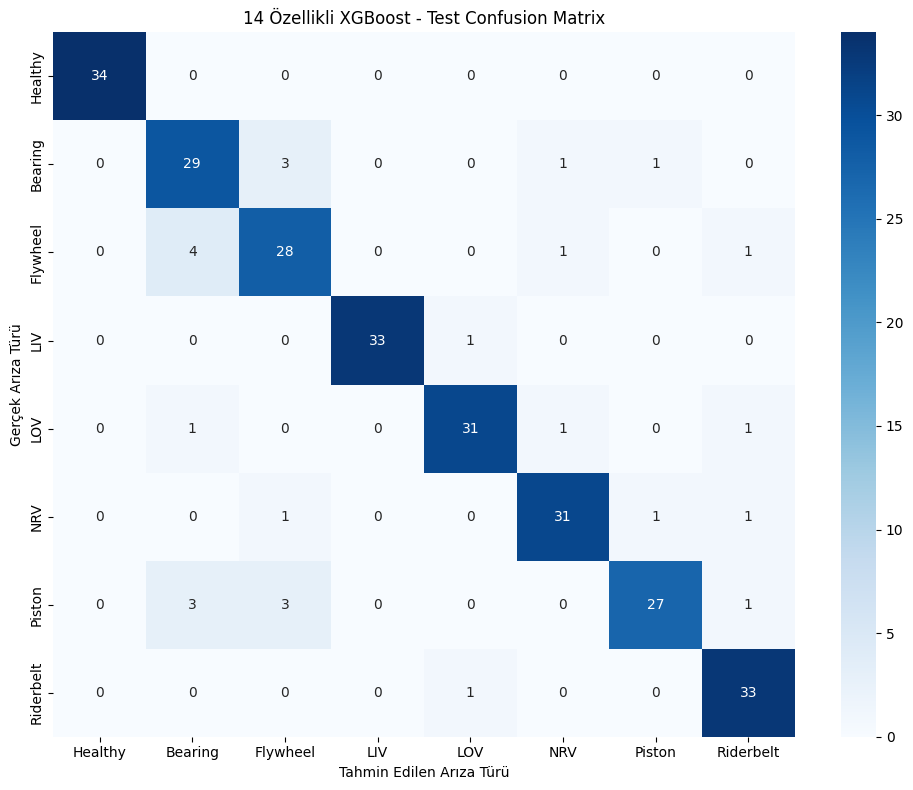


TEST TAHMİN SAYILARI
Doğru tahmin: 246
Yanlış tahmin: 26
Toplam test kaydı: 272


In [23]:

# 19. ADIM - NİHAİ MODELİN TEST VERİSİYLE DEĞERLENDİRİLMESİ

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 19.1. Test verilerinin hazırlanması
# Eğitimde kullanılan 14 özellik ve aynı sütun sırası korunuyor.

X_test_14 = ozellik_tablosu_14.loc[
    X_test_multi.index,
    X_train_14.columns
].copy()

# 19.2. Eğitilmiş model ile test tahminlerinin yapılması
# Model yeniden eğitilmiyor.

y_test_pred_14 = model_multi_14.predict(X_test_14)

# 19.3. Test performans metriklerinin hesaplanması

test_accuracy_14 = accuracy_score(
    y_test_multi, y_test_pred_14
)

test_precision_14 = precision_score(
    y_test_multi, y_test_pred_14,
    average="macro", zero_division=0
)

test_recall_14 = recall_score(
    y_test_multi, y_test_pred_14,
    average="macro", zero_division=0
)

test_f1_14 = f1_score(
    y_test_multi, y_test_pred_14,
    average="macro", zero_division=0
)

print("14 ÖZELLİKLİ XGBOOST - TEST SONUÇLARI")
print("-" * 55)

print(f"Test Accuracy:        %{test_accuracy_14 * 100:.2f}")
print(f"Test Macro Precision: %{test_precision_14 * 100:.2f}")
print(f"Test Macro Recall:    %{test_recall_14 * 100:.2f}")
print(f"Test Macro F1:        %{test_f1_14 * 100:.2f}")

# 19.4. Validation ve test karşılaştırması

performans_19 = pd.DataFrame({
    "Metrik": ["Accuracy", "Macro F1"],
    "Validation (%)": [
        val_acc_14 * 100,
        val_f1_14 * 100
    ],
    "Test (%)": [
        test_accuracy_14 * 100,
        test_f1_14 * 100
    ]
})

performans_19["Fark (Test - Validation)"] = (
    performans_19["Test (%)"]
    - performans_19["Validation (%)"]
)

print("\nVALIDATION - TEST KARŞILAŞTIRMASI")
print(performans_19.round(2).to_string(index=False))

# 19.5. Sınıf bazında test raporu

sinif_adlari_19 = [
    "Healthy", "Bearing", "Flywheel", "LIV",
    "LOV", "NRV", "Piston", "Riderbelt"
]

print("\nSINIF BAZINDA TEST RAPORU")
print("-" * 55)

print(classification_report(
    y_test_multi,
    y_test_pred_14,
    labels=list(range(8)),
    target_names=sinif_adlari_19,
    digits=4,
    zero_division=0
))

# 19.6. Test Confusion Matrix

cm_test_14 = confusion_matrix(
    y_test_multi,
    y_test_pred_14,
    labels=list(range(8))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_test_14,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sinif_adlari_19,
    yticklabels=sinif_adlari_19
)

plt.title("14 Özellikli XGBoost - Test Confusion Matrix")
plt.xlabel("Tahmin Edilen Arıza Türü")
plt.ylabel("Gerçek Arıza Türü")

plt.tight_layout()
plt.show()

# 19.7. Doğru ve yanlış tahminlerin sayısı

dogru_tahmin = (y_test_multi == y_test_pred_14).sum()
yanlis_tahmin = len(y_test_multi) - dogru_tahmin

print("\nTEST TAHMİN SAYILARI")
print(f"Doğru tahmin: {dogru_tahmin}")
print(f"Yanlış tahmin: {yanlis_tahmin}")
print(f"Toplam test kaydı: {len(y_test_multi)}")


In [24]:
# 20. ADIM - NİHAİ MODELİN KAYDEDİLMESİ
from google.colab import drive
drive.mount('/content/drive')
import os, json

kayit_klasoru = "/content/drive/MyDrive/Colab Notebooks/kompresor_model"
os.makedirs(kayit_klasoru, exist_ok=True)

model_multi_14.save_model(os.path.join(kayit_klasoru, "xgb_14_ozellik.json"))

with open(os.path.join(kayit_klasoru, "ozellik_sirasi.json"), "w", encoding="utf-8") as f:
    json.dump(list(X_train_14.columns), f, ensure_ascii=False)

print("Kaydedilen dosyalar:", os.listdir(kayit_klasoru))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Kaydedilen dosyalar: ['ornek_kayitlar', 'ozellik_sirasi.json', 'xgb_14_ozellik.json', 'guven_kontrolu.json', 'xgb_parca_mfcc_40.json', 'ozellik_sirasi_40.json', 'sekiller']


In [25]:
# 21. ADIM - YENİ SES KAYDI İÇİN TAHMİN FONKSİYONU
import numpy as np
import pandas as pd
from scipy.io import wavfile

SINIF_ADLARI = ["Healthy", "Bearing", "Flywheel", "LIV",
                "LOV", "NRV", "Piston", "Riderbelt"]
OZELLIK_SIRASI = list(X_train_14.columns)
HEDEF_UZUNLUK = 50000
EGITIM_STD = float(ozellik_tablosu_14["Standart_Sapma"].median())

def dosyadan_sinyal(yol):
    uzanti = os.path.splitext(yol)[1].lower()
    if uzanti == ".wav":
        _, s = wavfile.read(yol)
        s = np.asarray(s, dtype=float)
        if s.ndim > 1:                      # stereo -> mono
            s = s.mean(axis=1)
        if s.std() > 0:                     # genliği eğitim verisine benzet
            s = (s - s.mean()) / s.std() * EGITIM_STD
    else:                                   # .dat / .csv / .txt
        s = sinyal_oku(yol)
    if len(s) < 2:
        raise ValueError("Dosyada yeterli veri yok.")
    return s[:HEDEF_UZUNLUK]

def tahmin_et(yol):
    s = dosyadan_sinyal(yol)
    oz = {**ozellik_cikar(s), **yeni_ozellik_cikar(s)}
    X = pd.DataFrame([oz])[OZELLIK_SIRASI]
    p = model_multi_14.predict_proba(X)[0]
    sira = np.argsort(p)[::-1]
    return {SINIF_ADLARI[i]: float(p[i]) for i in sira}, len(s)

# Kontrol: test kümesinden bir dosyayı fonksiyonla tahmin et
ornek = ozellik_tablosu_14.loc[X_test_multi.index[0]]
olasiliklar, _ = tahmin_et(ornek["Dosya_Yolu"])
print("Gerçek:", ornek["Ariza_Turu"])
print("Tahmin:", next(iter(olasiliklar)), f"(%{max(olasiliklar.values())*100:.1f})")

Gerçek: Riderbelt
Tahmin: Riderbelt (%92.4)


In [26]:
# 23. ADIM - ARAYÜZDE DENEMEK İÇİN ÖRNEK KAYITLAR
import shutil

ornek_klasor = "/content/drive/MyDrive/Colab Notebooks/kompresor_model/ornek_kayitlar"
os.makedirs(ornek_klasor, exist_ok=True)

test_tablosu = ozellik_tablosu_14.loc[X_test_multi.index]
for sinif, grup in test_tablosu.groupby("Ariza_Turu"):
    for _, satir in grup.head(2).iterrows():
        yeni_ad = f"{sinif}_{satir['Dosya']}"
        shutil.copy(satir["Dosya_Yolu"], os.path.join(ornek_klasor, yeni_ad))

print(len(os.listdir(ornek_klasor)), "örnek kayıt kopyalandı:")
print(sorted(os.listdir(ornek_klasor)))

48 örnek kayıt kopyalandı:
['Bearing_preprocess_Reading166.dat', 'Bearing_preprocess_Reading168.dat', 'Bearing_preprocess_Reading19.dat', 'Bearing_preprocess_Reading210.dat', 'Bearing_preprocess_Reading25.dat', 'Bearing_preprocess_Reading69.dat', 'Flywheel_preprocess_Reading166.dat', 'Flywheel_preprocess_Reading168.dat', 'Flywheel_preprocess_Reading19.dat', 'Flywheel_preprocess_Reading210.dat', 'Flywheel_preprocess_Reading25.dat', 'Flywheel_preprocess_Reading69.dat', 'Healthy_preprocess_Reading166.dat', 'Healthy_preprocess_Reading168.dat', 'Healthy_preprocess_Reading19.dat', 'Healthy_preprocess_Reading210.dat', 'Healthy_preprocess_Reading25.dat', 'Healthy_preprocess_Reading69.dat', 'LIV_preprocess_Reading166.dat', 'LIV_preprocess_Reading168.dat', 'LIV_preprocess_Reading19.dat', 'LIV_preprocess_Reading210.dat', 'LIV_preprocess_Reading25.dat', 'LIV_preprocess_Reading69.dat', 'LOV_preprocess_Reading166.dat', 'LOV_preprocess_Reading168.dat', 'LOV_preprocess_Reading19.dat', 'LOV_preprocess_

In [27]:
# 24. ADIM - KAYITLARIN PARÇALARA BÖLÜNMESİ VE MFCC ÖZELLİKLERİ
import time
import numpy as np
import pandas as pd
import librosa

PARCA_SAYISI = 5
PARCA_UZUNLUGU = 10000      # 50.000 / 5
ORNEKLEME_HIZI = 10000      # Varsayım: 5 sn kayıt = 50.000 örnek
N_MFCC = 13

def mfcc_ozellikleri(parca):
    m = librosa.feature.mfcc(
        y=np.asarray(parca, dtype=np.float32), sr=ORNEKLEME_HIZI,
        n_mfcc=N_MFCC, n_fft=512, hop_length=256, n_mels=40
    )
    oz = {}
    for i in range(N_MFCC):
        oz[f"MFCC_{i+1}_Ort"] = float(m[i].mean())
        oz[f"MFCC_{i+1}_Std"] = float(m[i].std())
    return oz

def parca_ozellikleri(sinyal):
    satirlar = []
    for k in range(PARCA_SAYISI):
        parca = sinyal[k * PARCA_UZUNLUGU:(k + 1) * PARCA_UZUNLUGU]
        if len(parca) < PARCA_UZUNLUGU:
            break
        oz = {**ozellik_cikar(parca),
              **yeni_ozellik_cikar(parca),
              **mfcc_ozellikleri(parca)}
        oz["Parca_No"] = k
        satirlar.append(oz)
    return satirlar

baslangic = time.time()
parca_listesi = []

for sayac, (kayit_id, satir) in enumerate(ozellik_tablosu_multi.iterrows(), 1):
    sinyal = sinyal_oku(satir["Dosya_Yolu"])
    for oz in parca_ozellikleri(sinyal):
        oz["Kayit_ID"] = kayit_id
        oz["Etiket_Multi"] = int(satir["Etiket_Multi"])
        parca_listesi.append(oz)
    if sayac % 300 == 0:
        print(f"{sayac} / {len(ozellik_tablosu_multi)} kayıt işlendi...")

parca_tablosu = pd.DataFrame(parca_listesi)

print(f"\nSüre: {time.time() - baslangic:.0f} sn")
print("Parça tablosunun boyutu:", parca_tablosu.shape)
print("Kayıt başına parça sayısı:",
      parca_tablosu.groupby("Kayit_ID").size().value_counts().to_dict())
print("Eksik değer:", int(parca_tablosu.isna().sum().sum()))
print("Sonsuz değer:",
      int(np.isinf(parca_tablosu.select_dtypes("number")).sum().sum()))

300 / 1800 kayıt işlendi...
600 / 1800 kayıt işlendi...
900 / 1800 kayıt işlendi...
1200 / 1800 kayıt işlendi...
1500 / 1800 kayıt işlendi...
1800 / 1800 kayıt işlendi...

Süre: 82 sn
Parça tablosunun boyutu: (9000, 43)
Kayıt başına parça sayısı: {5: 1800}
Eksik değer: 0
Sonsuz değer: 0


In [28]:
# 25. ADIM - PARÇA TABANLI MODELLER VE KAYIT BAZINDA OYLAMA
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

ozellik_14 = list(X_train_14.columns)
mfcc_sutunlari = [c for c in parca_tablosu.columns if c.startswith("MFCC_")]
ozellik_40 = ozellik_14 + mfcc_sutunlari

egitim_p = parca_tablosu[parca_tablosu["Kayit_ID"].isin(X_train_multi.index)]
val_p = parca_tablosu[parca_tablosu["Kayit_ID"].isin(X_val_multi.index)]
test_p = parca_tablosu[parca_tablosu["Kayit_ID"].isin(X_test_multi.index)]

print("Parça sayıları -> Eğitim:", len(egitim_p),
      "| Validation:", len(val_p), "| Test:", len(test_p))

def yeni_model():
    return XGBClassifier(
        n_estimators=100, max_depth=3, learning_rate=0.05,
        objective="multi:softprob", num_class=8,
        eval_metric="mlogloss", random_state=42
    )

def kayit_bazinda(model, tablo, sutunlar):
    """5 parçanın olasılıklarının ortalaması alınır, en yüksek sınıf seçilir."""
    olas = pd.DataFrame(model.predict_proba(tablo[sutunlar]), index=tablo.index)
    olas["Kayit_ID"] = tablo["Kayit_ID"].values
    ortalama = olas.groupby("Kayit_ID").mean()
    tahmin = ortalama.values.argmax(axis=1)
    gercek = (tablo.groupby("Kayit_ID")["Etiket_Multi"].first()
              .loc[ortalama.index].values)
    return gercek, tahmin

modeller_25 = {}
sonuclar_25 = []

for ad, sutunlar in [("Parça + 14 özellik", ozellik_14),
                     ("Parça + 14 özellik + MFCC", ozellik_40)]:
    m = yeni_model()
    m.fit(egitim_p[sutunlar], egitim_p["Etiket_Multi"])
    modeller_25[ad] = (m, sutunlar)

    g_tr, t_tr = kayit_bazinda(m, egitim_p, sutunlar)
    g_va, t_va = kayit_bazinda(m, val_p, sutunlar)
    parca_val_acc = accuracy_score(val_p["Etiket_Multi"],
                                   m.predict(val_p[sutunlar]))

    sonuclar_25.append({
        "Model": ad,
        "Özellik sayısı": len(sutunlar),
        "Eğitim Acc (%)": accuracy_score(g_tr, t_tr) * 100,
        "Validation Acc (%)": accuracy_score(g_va, t_va) * 100,
        "Validation Macro F1 (%)": f1_score(g_va, t_va, average="macro") * 100,
        "Tek parça Val Acc (%)": parca_val_acc * 100,
    })

sonuclar_25.insert(0, {
    "Model": "ESKİ: Tüm kayıt, 14 özellik",
    "Özellik sayısı": 14,
    "Eğitim Acc (%)": train_acc_14 * 100,
    "Validation Acc (%)": val_acc_14 * 100,
    "Validation Macro F1 (%)": val_f1_14 * 100,
    "Tek parça Val Acc (%)": float("nan"),
})

tablo_25 = pd.DataFrame(sonuclar_25)
tablo_25["Ezber farkı (puan)"] = (tablo_25["Eğitim Acc (%)"]
                                 - tablo_25["Validation Acc (%)"])

print("\nKAYIT BAZINDA KARŞILAŞTIRMA (Validation)")
print(tablo_25.round(2).to_string(index=False))

en_iyi_ad = tablo_25.iloc[1:].sort_values(
    "Validation Macro F1 (%)", ascending=False).iloc[0]["Model"]
print("\nValidation'a göre en iyi yeni model:", en_iyi_ad)

Parça sayıları -> Eğitim: 6280 | Validation: 1360 | Test: 1360

KAYIT BAZINDA KARŞILAŞTIRMA (Validation)
                      Model  Özellik sayısı  Eğitim Acc (%)  Validation Acc (%)  Validation Macro F1 (%)  Tek parça Val Acc (%)  Ezber farkı (puan)
ESKİ: Tüm kayıt, 14 özellik              14           95.30               85.66                    85.56                    NaN                9.64
         Parça + 14 özellik              14           90.92               86.76                    86.34                  79.34                4.16
  Parça + 14 özellik + MFCC              40           99.84               99.26                    99.26                  95.74                0.58

Validation'a göre en iyi yeni model: Parça + 14 özellik + MFCC


TEST SONUÇLARI (Parça + 14 özellik + MFCC)
-------------------------------------------------------
                              Eski model  Yeni model
Test Accuracy                     90.44%      98.53%
Test Macro F1                     90.47%      98.53%

SINIF BAZINDA TEST RAPORU (yeni model)
              precision    recall  f1-score   support

     Healthy     1.0000    1.0000    1.0000        34
     Bearing     1.0000    1.0000    1.0000        34
    Flywheel     0.9189    1.0000    0.9577        34
         LIV     1.0000    1.0000    1.0000        34
         LOV     0.9714    1.0000    0.9855        34
         NRV     1.0000    1.0000    1.0000        34
      Piston     1.0000    0.9118    0.9538        34
   Riderbelt     1.0000    0.9706    0.9851        34

    accuracy                         0.9853       272
   macro avg     0.9863    0.9853    0.9853       272
weighted avg     0.9863    0.9853    0.9853       272



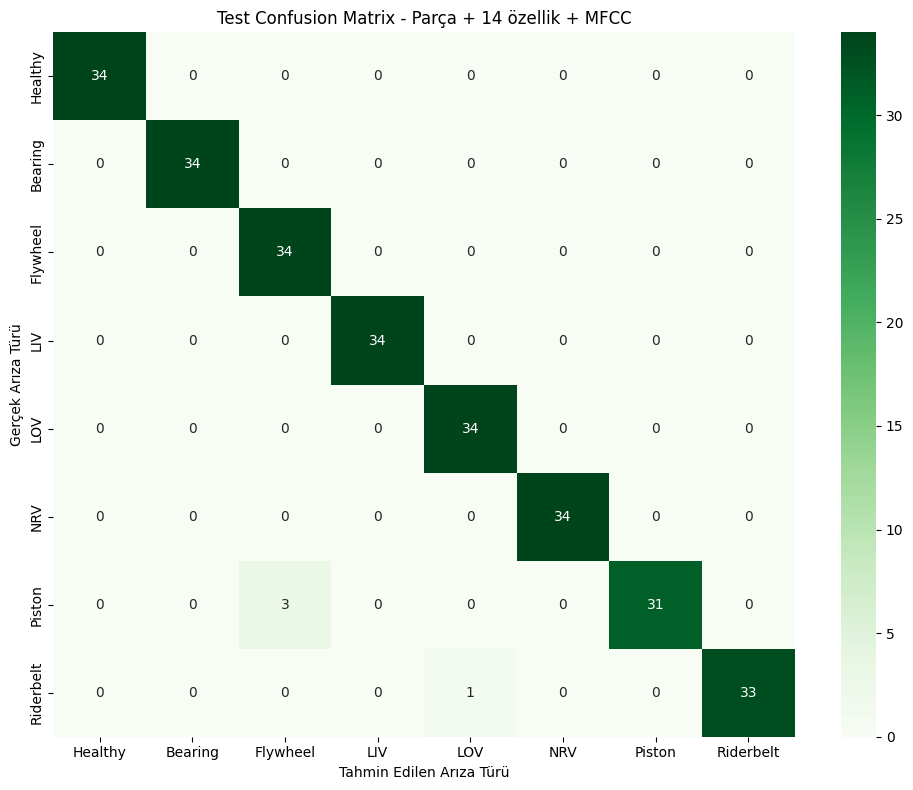

In [29]:
# 26. ADIM - SEÇİLEN MODELİN TEST VERİSİYLE DEĞERLENDİRİLMESİ
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

model_26, sutunlar_26 = modeller_25[en_iyi_ad]
g_te, t_te = kayit_bazinda(model_26, test_p, sutunlar_26)

yeni_test_acc = accuracy_score(g_te, t_te)
yeni_test_f1 = f1_score(g_te, t_te, average="macro")
eski_test_acc = accuracy_score(y_test_multi, y_test_pred_14)
eski_test_f1 = f1_score(y_test_multi, y_test_pred_14, average="macro")

print(f"TEST SONUÇLARI ({en_iyi_ad})")
print("-" * 55)
print(f"{'':28}{'Eski model':>12}{'Yeni model':>12}")
print(f"{'Test Accuracy':28}{eski_test_acc*100:>11.2f}%{yeni_test_acc*100:>11.2f}%")
print(f"{'Test Macro F1':28}{eski_test_f1*100:>11.2f}%{yeni_test_f1*100:>11.2f}%")

print("\nSINIF BAZINDA TEST RAPORU (yeni model)")
print(classification_report(g_te, t_te, labels=list(range(8)),
                            target_names=SINIF_ADLARI, digits=4,
                            zero_division=0))

plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(g_te, t_te, labels=list(range(8))),
            annot=True, fmt="d", cmap="Greens",
            xticklabels=SINIF_ADLARI, yticklabels=SINIF_ADLARI)
plt.title(f"Test Confusion Matrix - {en_iyi_ad}")
plt.xlabel("Tahmin Edilen Arıza Türü")
plt.ylabel("Gerçek Arıza Türü")
plt.tight_layout()
plt.show()

In [31]:
# 27. ADIM - GÜVEN KONTROLÜ: TANIDIK OLMAYAN KAYITLARIN TESPİTİ
# Eğitim parçalarının 40 özelliğinden bir "tanıdıklık" ölçüsü kurulur
# (Mahalanobis mesafesi). Eşik, modelin hiç görmediği validation kayıtlarından
# belirlenir; test kümesiyle yanlış uyarı oranı kontrol edilir.

import os, json
import numpy as np
import pandas as pd
from sklearn.covariance import LedoitWolf

# 27.1. Eğitim parçalarına göre ölçekleme ve kovaryans
X_egitim_guven = egitim_p[sutunlar_26].values.astype(float)
guven_ort = X_egitim_guven.mean(axis=0)
guven_sap = X_egitim_guven.std(axis=0)
guven_sap[guven_sap == 0] = 1.0

lw = LedoitWolf().fit((X_egitim_guven - guven_ort) / guven_sap)

def kayit_mesafeleri(tablo):
    """Her parçanın eğitim verisine uzaklığı; kayıt için 5 parçanın ortalaması."""
    z = (tablo[sutunlar_26].values.astype(float) - guven_ort) / guven_sap
    d = np.sqrt(lw.mahalanobis(z))
    return pd.Series(d).groupby(tablo["Kayit_ID"].values).mean()

# 27.2. Eşik: validation kayıtlarının %99'unun altında kaldığı değer
mesafe_val = kayit_mesafeleri(val_p)
guven_esik = float(np.percentile(mesafe_val, 99))

# 27.3. Kontrol: test kayıtlarının kaçı yanlışlıkla "tanıdık değil" sayılıyor?
mesafe_test = kayit_mesafeleri(test_p)
mesafe_egitim = kayit_mesafeleri(egitim_p)

print("GÜVEN KONTROLÜ")
print("-" * 55)
print(f"Eşik (benzerlik mesafesi): {guven_esik:.2f}")
print(f"Eğitim kayıtları  - ortalama mesafe: {mesafe_egitim.mean():.2f}")
print(f"Validation kayıtl.- ortalama mesafe: {mesafe_val.mean():.2f}")
print(f"Test kayıtları    - ortalama mesafe: {mesafe_test.mean():.2f}")
print(f"\nTestte yanlışlıkla uyarı alan kayıt: "
      f"{(mesafe_test > guven_esik).sum()} / {len(mesafe_test)} "
      f"(%{(mesafe_test > guven_esik).mean()*100:.1f})")

# 27.4. Drive'a kaydet (başlatıcı bu dosyaları kullanır)
# Model de burada kaydedilir; böylece model ve güven kontrolü hep aynı eğitimden gelir.
model_26.save_model(os.path.join(kayit_klasoru, "xgb_parca_mfcc_40.json"))
with open(os.path.join(kayit_klasoru, "ozellik_sirasi_40.json"), "w", encoding="utf-8") as f:
    json.dump(list(sutunlar_26), f, ensure_ascii=False)

with open(os.path.join(kayit_klasoru, "guven_kontrolu.json"), "w", encoding="utf-8") as f:
    json.dump({
        "ozellikler": list(sutunlar_26),
        "ortalama": guven_ort.tolist(),
        "sapma": guven_sap.tolist(),
        "merkez": lw.location_.tolist(),
        "hassasiyet": lw.precision_.tolist(),
        "esik": guven_esik,
    }, f)

print("\nKaydedildi: xgb_parca_mfcc_40.json, ozellik_sirasi_40.json, guven_kontrolu.json")


GÜVEN KONTROLÜ
-------------------------------------------------------
Eşik (benzerlik mesafesi): 9.56
Eğitim kayıtları  - ortalama mesafe: 5.92
Validation kayıtl.- ortalama mesafe: 5.90
Test kayıtları    - ortalama mesafe: 5.89

Testte yanlışlıkla uyarı alan kayıt: 2 / 272 (%0.7)

Kaydedildi: xgb_parca_mfcc_40.json, ozellik_sirasi_40.json, guven_kontrolu.json


GENEL ÖZELLİK ÖNEMİ (ilk 15)
---------------------------------------------
 1. MFCC_6_Ort             0.4828  (MFCC)
 2. MFCC_9_Ort             0.4013  (MFCC)
 3. MFCC_12_Ort            0.3562  (MFCC)
 4. Spectral_Rolloff       0.2522
 5. MFCC_11_Ort            0.1868  (MFCC)
 6. MFCC_5_Ort             0.1629  (MFCC)
 7. MFCC_1_Ort             0.1299  (MFCC)
 8. MFCC_3_Ort             0.1278  (MFCC)
 9. MFCC_8_Ort             0.1109  (MFCC)
10. MFCC_4_Ort             0.0915  (MFCC)
11. MFCC_7_Ort             0.0874  (MFCC)
12. MFCC_13_Ort            0.0744  (MFCC)
13. Orta_Bant_Enerjisi     0.0640
14. MFCC_8_Std             0.0628  (MFCC)
15. Dusuk_Bant_Enerjisi    0.0568

Toplam önemin %83.8'i MFCC özelliklerinden geliyor (40 özelliğin 26'sı MFCC).


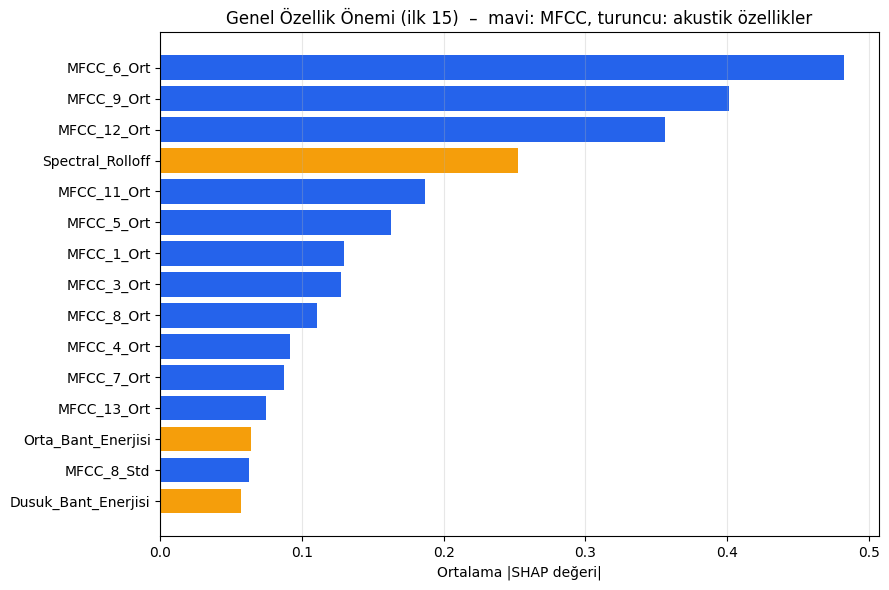

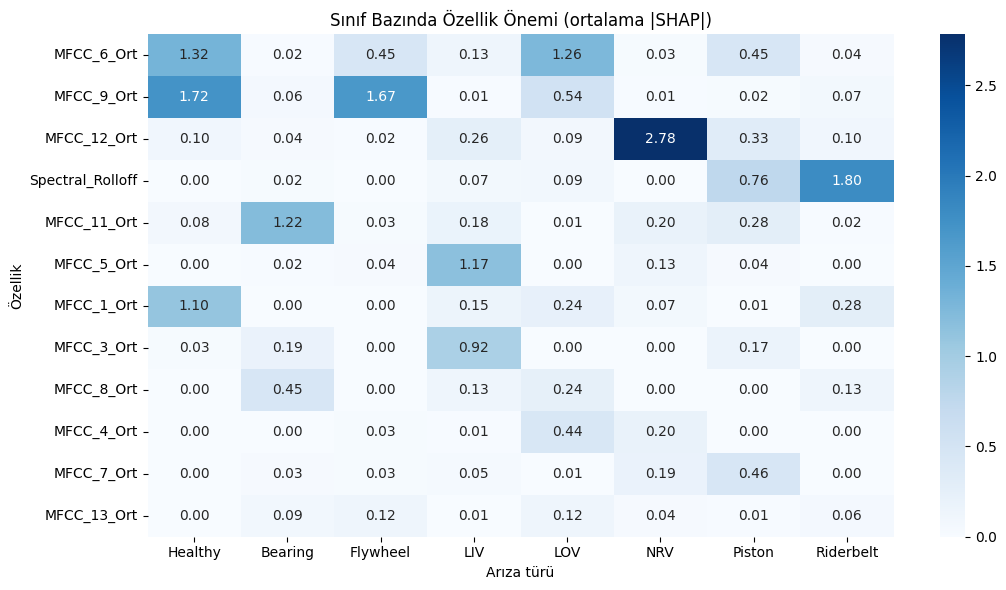


HER SINIFIN EN BELİRLEYİCİ 3 ÖZELLİĞİ
---------------------------------------------
Healthy   : MFCC_9_Ort, MFCC_6_Ort, MFCC_1_Ort
Bearing   : MFCC_11_Ort, MFCC_8_Ort, Spektral_Entropi
Flywheel  : MFCC_9_Ort, MFCC_6_Ort, MFCC_8_Std
LIV       : MFCC_5_Ort, MFCC_3_Ort, Orta_Bant_Enerjisi
LOV       : MFCC_6_Ort, MFCC_9_Ort, MFCC_4_Ort
NRV       : MFCC_12_Ort, Dusuk_Bant_Enerjisi, MFCC_11_Ort
Piston    : Spectral_Rolloff, MFCC_7_Ort, MFCC_6_Ort
Riderbelt : Spectral_Rolloff, MFCC_3_Std, MFCC_1_Ort

PISTON'U FLYWHEEL'DEN AYIRAN İLK 5 ÖZELLİK
---------------------------------------------
Spectral_Rolloff       Piston ort.:    0.0347 | Flywheel ort.:    0.0459
MFCC_7_Ort             Piston ort.:    6.0891 | Flywheel ort.:    4.4273
MFCC_4_Std             Piston ort.:    7.1473 | Flywheel ort.:    5.9476
MFCC_6_Ort             Piston ort.:   11.1086 | Flywheel ort.:    9.9552
MFCC_11_Ort            Piston ort.:   -4.1387 | Flywheel ort.:   -3.6372

Şekiller ve tablolar kaydedildi: /content/dri

In [32]:
# 28. ADIM - SHAP İLE AÇIKLANABİLİRLİK
# XGBoost'un yerleşik SHAP hesabı kullanılır (ek kütüphane gerekmez).
# Analiz, modelin eğitimde görmediği test parçaları üzerinde yapılır.

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

sekil_klasoru = os.path.join(kayit_klasoru, "sekiller")
os.makedirs(sekil_klasoru, exist_ok=True)

def shap_degerleri(model, X):
    """(örnek, sınıf, özellik) boyutlu SHAP dizisi; sabit terim atılır."""
    katki = model.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)
    n, f = X.shape
    if katki.ndim == 2:                      # eski xgboost sürümleri
        katki = katki.reshape(n, -1, f + 1)
    return katki[:, :, :f]

X_shap = test_p[sutunlar_26]
y_shap = test_p["Etiket_Multi"].values
S = shap_degerleri(model_26, X_shap)          # (parça, 8 sınıf, 40 özellik)
mfcc_mi = pd.Series([c.startswith("MFCC_") for c in sutunlar_26], index=sutunlar_26)

# 28.1. Genel önem: tüm sınıflar ve parçalar üzerinden ortalama |SHAP|
genel_onem = pd.Series(np.abs(S).mean(axis=(0, 1)), index=sutunlar_26)
genel_onem = genel_onem.sort_values(ascending=False)
mfcc_payi = genel_onem[mfcc_mi[genel_onem.index]].sum() / genel_onem.sum()

print("GENEL ÖZELLİK ÖNEMİ (ilk 15)")
print("-" * 45)
for i, (ad, deger) in enumerate(genel_onem.head(15).items(), 1):
    print(f"{i:>2}. {ad:<22} {deger:.4f}{'  (MFCC)' if mfcc_mi[ad] else ''}")
print(f"\nToplam önemin %{mfcc_payi*100:.1f}'i MFCC özelliklerinden geliyor "
      f"(40 özelliğin 26'sı MFCC).")

ilk15 = genel_onem.head(15)[::-1]
plt.figure(figsize=(9, 6))
plt.barh(ilk15.index, ilk15.values,
         color=["#2563EB" if mfcc_mi[a] else "#F59E0B" for a in ilk15.index])
plt.xlabel("Ortalama |SHAP değeri|")
plt.title("Genel Özellik Önemi (ilk 15)  –  mavi: MFCC, turuncu: akustik özellikler")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(sekil_klasoru, "shap_genel_onem.png"), dpi=200)
plt.show()

# 28.2. Sınıf bazında önem: her sınıfın kendi kayıtlarında, o sınıfın kararına etki
sinif_onem = pd.DataFrame({
    ad: np.abs(S[y_shap == k, k, :]).mean(axis=0)
    for k, ad in enumerate(SINIF_ADLARI)
}, index=sutunlar_26)

ilk_ozellikler = genel_onem.head(12).index
plt.figure(figsize=(11, 6))
sns.heatmap(sinif_onem.loc[ilk_ozellikler], annot=True, fmt=".2f", cmap="Blues")
plt.title("Sınıf Bazında Özellik Önemi (ortalama |SHAP|)")
plt.xlabel("Arıza türü"); plt.ylabel("Özellik")
plt.tight_layout()
plt.savefig(os.path.join(sekil_klasoru, "shap_sinif_onem.png"), dpi=200)
plt.show()

print("\nHER SINIFIN EN BELİRLEYİCİ 3 ÖZELLİĞİ")
print("-" * 45)
for ad in SINIF_ADLARI:
    print(f"{ad:<10}: " + ", ".join(sinif_onem[ad].nlargest(3).index))

# 28.3. Piston ile Flywheel'i ayıran özellikler (en çok karışan ikili)
p, fw = SINIF_ADLARI.index("Piston"), SINIF_ADLARI.index("Flywheel")
fark = (S[y_shap == p, p, :].mean(axis=0)
        - S[y_shap == fw, p, :].mean(axis=0))
fark = pd.Series(fark, index=sutunlar_26).sort_values(key=np.abs, ascending=False)

print("\nPISTON'U FLYWHEEL'DEN AYIRAN İLK 5 ÖZELLİK")
print("-" * 45)
for ad in fark.head(5).index:
    print(f"{ad:<22} Piston ort.: {X_shap[y_shap == p][ad].mean():>9.4f} | "
          f"Flywheel ort.: {X_shap[y_shap == fw][ad].mean():>9.4f}")

# 28.4. Tablolar da rapor için kaydedilir
genel_onem.to_csv(os.path.join(sekil_klasoru, "shap_genel_onem.csv"))
sinif_onem.to_csv(os.path.join(sekil_klasoru, "shap_sinif_onem.csv"))
print(f"\nŞekiller ve tablolar kaydedildi: {sekil_klasoru}")
